# 03 — Market Activity, Expansion, Concentration & Dynamics
**Dubai Real Estate Analytics V2 · RQ04 (flagship), RQ05 (core), RQ06 (exploratory)**

**Scope.** Frozen DLD registered sale transactions; **P0** eligible sales for market-activity estimands, 2010–2025 completed calendar years; primary 2021–2025 endpoints. P1 Core/Strict are independently labeled sensitivity populations. The notebook tests whether activity growth is sustained and geographically broad, distinguishes registered market-scale expansion from Off-Plan share reallocation, and conditionally tests whether preceding activity is informative about subsequent *observed* residential price change.

**Not permitted:** interpreting sales registrations as unique homes, housing-stock turnover, buyer demand, transactions completed on site, cash flow, capital inflows, developer receipts, Ready=resale, or causal explanations. Source rows are never modified or imputed; 2026 is provisional and excluded from all primary historical estimates.

## 02 — Research estimands and inherited constraints

**P0 annual/quarterly activity:** $N_t=\sum_i1(i\in P0,t_i=t)$ and registered nominal consideration $V_t=\sum_i price_i$. If $N_t>0$, $\bar P_t=V_t/N_t$ and $\Delta\log V=\Delta\log N+\Delta\log\bar P$ for positive endpoints. Counts and nominal value are **administrative accounting**, not an economic stock-flow estimate.

**RQ05:** $O_t=N_t S_t$ with $S_t=O_t/N_t$, where Off-Plan is one source registration category; classify missing/other registration as **Unknown**, never silently drop it. Exact symmetric change: $\Delta O=\Delta N\bar S+\Delta S\bar N$. For a stable exhaustive property grouping $k$, $S_t=\sum_k w_{kt}r_{kt}$ and $\Delta S=\sum_k\bar w_k\Delta r_k+\sum_k\bar r_k\Delta w_k$ only for categories with defined endpoint rates. Category entry/exit is an explicit residual, not a fabricated rate.

**RQ04:** Community activity is defined by source `area_id`; known-geography transaction shares sum to one within their own universe. HHI=$\sum_a s_a^2$. Common-community and 2021-fixed universes are different estimands, requiring separate coverage. Observed community entry is **not** proof of new construction.

**RQ06:** Price outcomes use P1 Strict and are composition-sensitive unless matched support is explicitly established; observational correlations and time-split forecasts cannot establish causality. Notebook 02 reported QUALIFIED matched prices, not a constant-quality index. Notebook 00 documented uneven bedroom coverage, especially Ready villas; P2 should **not** be used to count activity.

Research decisions: **SUPPORTED** (verified observation), **QUALIFIED** (robust restricted observation), **INCONCLUSIVE** (insufficient support/unstable inference), **BLOCKED** (failed critical validation).

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, calendar, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'loader.py').exists() and (p/'data'/'raw'/'dld_sales_transactions.parquet').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from Dubai_Real_Estate_Analytics_V2 or notebooks/ with src/ and data/raw present')
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.loader import load_and_validate
from src.cleaning import clean_transactions, cohort_audit
from src.features import engineer_features

SHA='8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e'
START_YEAR, END_YEAR, T0, T1 = 2010, 2025, 2021, 2025
TABLES=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'; AGG=ROOT/'data'/'aggregates'
for folder in (TABLES, FIG, AGG): folder.mkdir(parents=True,exist_ok=True)
raw, source, validation = load_and_validate(root=ROOT, expected_sha256=SHA, strict=True)
assert validation.passed and source.sha256==SHA and len(raw)==source.row_count
source_manifest=pd.DataFrame([dict(source_sha256=source.sha256,source_rows=len(raw),source_columns=len(raw.columns),python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,analysis_window='2010–2025',primary_comparison='2021–2025',notebook='03_Market_Activity')])
display(source_manifest)
print('Source validation:',len(validation.errors),'errors,',len(validation.warnings),'warnings')

,source_sha256,source_rows,source_columns,python,pandas,numpy,analysis_window,primary_comparison,notebook
0,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,1382848,20,3.11.18,2.3.3,2.4.6,2010–2025,2021–2025,03_Market_Activity


Source validation: 0 errors, 6 warnings


In [2]:
cleaned=clean_transactions(raw)
engineered=engineer_features(cleaned)
assert len(raw)==len(engineered) and raw.index.equals(engineered.index)
for col in raw.columns: pd.testing.assert_series_equal(raw[col],engineered[col])
cohort_summary=cohort_audit(cleaned)
historical=engineered.year.between(START_YEAR,END_YEAR).fillna(False)
p0_mask=engineered.eligible_market_activity & historical
p1_mask=engineered.eligible_residential_core & historical
strict_mask=engineered.eligible_residential_strict & historical
assert not (strict_mask & ~p1_mask).any() and not (p1_mask & ~p0_mask).any()
assert int(p0_mask.sum())==1134513, f'P0 historical snapshot count changed: {int(p0_mask.sum())}'
assert int(strict_mask.sum())==901642, f'P1 strict snapshot count changed: {int(strict_mask.sum())}'
# Frame copied once; unknown category and geography stay observable and separately counted.
cols=['transaction_id','instance_date','year','month','quarter','area_id','area_name_en','property_type_label','usage_label','reg_type_label','price_aed','procedure_id','procedure_name_en','is_pre_registration']
p0=engineered.loc[p0_mask,cols].copy()
p0['year']=p0.year.astype('int16');p0['month']=p0.month.astype('int8');p0['quarter']=p0.quarter.astype('int8')
p0['reg']=p0.reg_type_label.where(p0.reg_type_label.isin(['Ready','Off-Plan']),'Unknown').astype('string')
p0['ptype']=p0.property_type_label.fillna('Unknown').astype('string')
p0['usage']=p0.usage_label.fillna('Unknown').astype('string')
p0['area_key']=p0.area_id.astype('string');p0['area_known']=p0.area_key.notna()
p0['period']=pd.PeriodIndex.from_fields(year=p0.year.astype(int),quarter=p0.quarter.astype(int),freq='Q')
p0['month_period']=pd.PeriodIndex.from_fields(year=p0.year.astype(int),month=p0.month.astype(int),freq='M')
p0['price_aed']=pd.to_numeric(p0.price_aed,errors='raise')
assert np.isfinite(p0.price_aed.to_numpy()).all() and (p0.price_aed>=0).all()
assert p0.transaction_id.is_unique and len(p0)==int(p0_mask.sum())
cohort_reconciliation=pd.DataFrame([{'population':'P0_ALL_SALES','historical_n':len(p0)},{'population':'P1_RESIDENTIAL_CORE','historical_n':int(p1_mask.sum())},{'population':'P1_STRICT','historical_n':int(strict_mask.sum())},{'population':'P2_KNOWN_SEGMENT','historical_n':int((engineered.eligible_known_segment & historical).sum())}])
display(cohort_reconciliation)

,population,historical_n
0,P0_ALL_SALES,1134513
1,P1_RESIDENTIAL_CORE,916748
2,P1_STRICT,901642
3,P2_KNOWN_SEGMENT,864170


## 05 — Prespecified comparison protocol

**Primary:** 2021 versus 2025; additional 2020 versus 2025 and all completed historical years 2010–2025. Annual totals reconcile to quarterly totals. Growth uses same-calendar-period comparisons; zero-base growth is *undefined*. Geographic groups use stable source `area_id` identifiers and missing geography as a separate term. Fixed-universe comparisons are never conflated with changing-universe results. Small denominators and sparsely represented early years are flagged rather than corrected by interpolation.

**Research additions over Notebook 01:** persistent quarterly growth and volatility, exact Off-Plan scale/share and within/between-property decompositions, cross-category divergence, common-universe geographic entry/exit accounting, concentration versus growth breadth, calendar-normalized monthly seasonality, and gated RQ06. Do not reinterpret Notebook 02's QUALIFIED residential-price movement as a verified citywide constant-quality price index.

## 06 — Temporal methodology

An observed transaction is counted in the source registration period. Quarterly year-on-year growth is compared with the same quarter one year earlier. Four-quarter rolling sums smooth noise but are serially dependent. Differences of year-on-year rates are *momentum diagnostics* and do not establish economic regime causes. Counts and registered values remain nominal; all historical data before 2026 are complete calendar years but may have nonuniform source capture.

In [3]:
activity_annual=p0.groupby('year',observed=True).agg(transactions=('transaction_id','size'),registered_value_aed=('price_aed','sum'),median_consideration_aed=('price_aed','median')).reset_index()
activity_annual['mean_consideration_aed']=activity_annual.registered_value_aed/activity_annual.transactions
activity_quarter=p0.groupby(['year','quarter'],observed=True).agg(transactions=('transaction_id','size'),registered_value_aed=('price_aed','sum')).reset_index().sort_values(['year','quarter'])
activity_quarter['period']=pd.PeriodIndex.from_fields(year=activity_quarter.year,quarter=activity_quarter.quarter,freq='Q').astype(str)
activity_quarter['mean_consideration_aed']=activity_quarter.registered_value_aed/activity_quarter.transactions
activity_period_panel=pd.concat([activity_annual.assign(frequency='annual',quarter=pd.NA,period=activity_annual.year.astype(str)),activity_quarter.assign(frequency='quarterly')],ignore_index=True)
assert int(activity_annual.transactions.sum())==len(p0)
assert np.isclose(activity_annual.registered_value_aed.sum(),p0.price_aed.sum(),rtol=1e-12)
assert activity_quarter.groupby('year').transactions.sum().reindex(activity_annual.year).to_numpy().tolist()==activity_annual.transactions.tolist()
assert np.allclose(activity_quarter.groupby('year').registered_value_aed.sum().reindex(activity_annual.year).to_numpy(),activity_annual.registered_value_aed.to_numpy(),rtol=1e-12)
print('Historical totals:',len(p0),'transactions;',len(activity_quarter),'observed quarters')
display(activity_annual.tail(6))

Historical totals: 1134513 transactions; 64 observed quarters


,year,transactions,registered_value_aed,median_consideration_aed,mean_consideration_aed
10,2020,33102,69237399748,1200000.0,2.091638e+06
11,2021,59424,148350178469,1448431.0,2.496469e+06
12,2022,95471,262437530423,1578555.0,2.748872e+06
13,2023,131801,408152113488,1547000.0,3.096730e+06
14,2024,179416,519915960524,1542858.0,2.897824e+06
15,2025,214803,682330410397,1550000.0,3.176540e+06


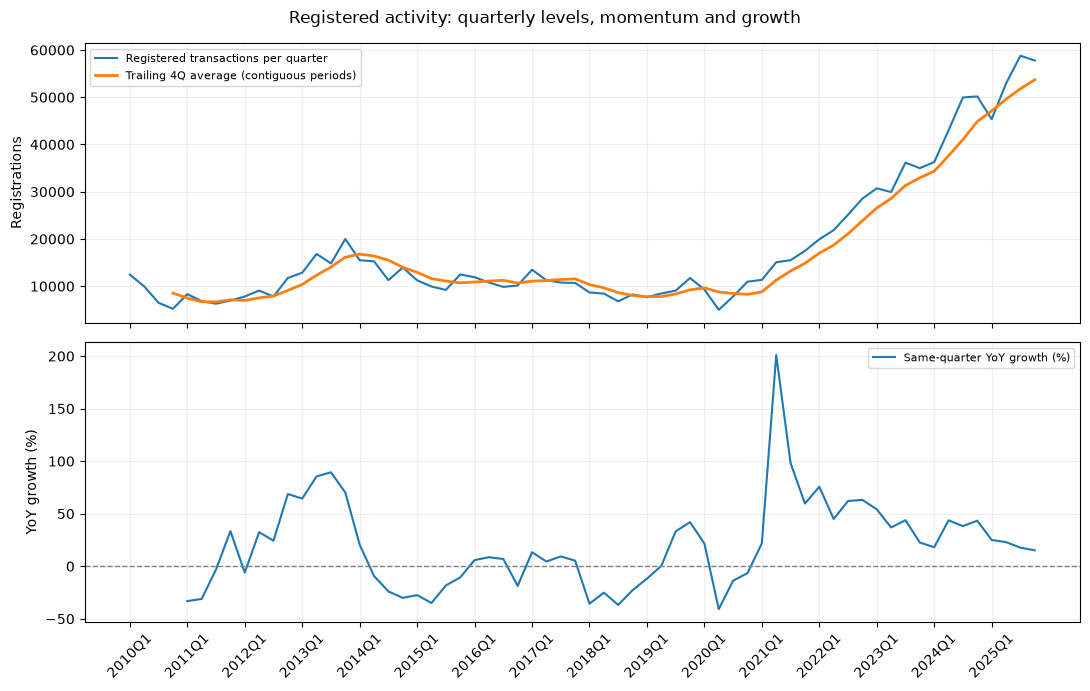

,year,quarter,transactions,yoy_pct,yoy_acceleration_pp,rolling_4q_n,rolling_8q_yoy_std_pp
52,2023,1,30726,54.146390,-21.536670,106264.0,50.505306
53,2023,2,29930,36.916743,-8.081930,114334.0,18.855524
54,2023,3,36152,43.819867,-18.270667,125349.0,12.642097
55,2023,4,34993,22.606075,-40.541289,131801.0,16.814959
56,2024,1,36279,18.072642,-36.073748,137354.0,16.789286
57,2024,2,43006,43.688607,6.771864,150430.0,16.775896
58,2024,3,49961,38.197057,-5.622810,164239.0,14.929303
59,2024,4,50170,43.371531,20.765456,179416.0,11.891235
60,2025,1,45353,25.011715,6.939073,188490.0,10.478047
61,2025,2,52893,22.989815,-20.698791,198377.0,11.057633


Cell 08 verified: quarterly growth, momentum and correctly labeled rolling volatility.


In [4]:

# ============================================================
# CELL 08 — Quarterly Growth, Momentum and Volatility
# ============================================================

q = activity_quarter.sort_values(
    ["year", "quarter"]
).copy()

# Match each quarter with the same quarter in the previous year.
previous = q[
    ["year", "quarter", "transactions", "registered_value_aed"]
].copy()

previous["year"] += 1

previous = previous.rename(columns={
    "transactions": "prev_year_transactions",
    "registered_value_aed": "prev_year_value_aed"
})

q = q.merge(
    previous,
    on=["year", "quarter"],
    how="left",
    validate="one_to_one"
).sort_values(["year", "quarter"])

# Signed count change and year-on-year growth.
q["yoy_delta_n"] = (
    q["transactions"] - q["prev_year_transactions"]
)

q["yoy_pct"] = np.where(
    q["prev_year_transactions"] > 0,
    100 * (
        q["transactions"] / q["prev_year_transactions"] - 1
    ),
    np.nan
)

q["yoy_value_pct"] = np.where(
    q["prev_year_value_aed"] > 0,
    100 * (
        q["registered_value_aed"] / q["prev_year_value_aed"] - 1
    ),
    np.nan
)

# Four-quarter trailing totals.
q["rolling_4q_n"] = (
    q["transactions"].rolling(4, min_periods=4).sum()
)

q["rolling_4q_value_aed"] = (
    q["registered_value_aed"]
    .rolling(4, min_periods=4)
    .sum()
)

# Compare a quarterly YoY growth rate with its value
# for the same quarter in the preceding year.
previous_rate = q[
    ["year", "quarter", "yoy_pct"]
].copy()

previous_rate["year"] += 1

previous_rate = previous_rate.rename(
    columns={"yoy_pct": "prev_yoy_pct"}
)

q = q.merge(
    previous_rate,
    on=["year", "quarter"],
    how="left",
    validate="one_to_one"
).sort_values(["year", "quarter"])

q["yoy_acceleration_pp"] = (
    q["yoy_pct"] - q["prev_yoy_pct"]
)

# Continuity checks: missing historical quarters must
# not be treated as adjacent observations.
period_ids = pd.PeriodIndex(q["period"], freq="Q")

q["contiguous_4q"] = False
q["contiguous_8q"] = False

for j in range(len(q)):
    if j >= 3:
        window = period_ids[j-3:j+1]
        q.iloc[
            j, q.columns.get_loc("contiguous_4q")
        ] = all(
            window[k].ordinal - window[k-1].ordinal == 1
            for k in range(1, len(window))
        )

    if j >= 7:
        window = period_ids[j-7:j+1]
        q.iloc[
            j, q.columns.get_loc("contiguous_8q")
        ] = all(
            window[k].ordinal - window[k-1].ordinal == 1
            for k in range(1, len(window))
        )

q.loc[
    ~q["contiguous_4q"],
    ["rolling_4q_n", "rolling_4q_value_aed"]
] = np.nan

# This is the sample standard deviation of eight
# consecutive quarterly YoY growth observations.
# It is NOT annualized volatility.
q["rolling_8q_yoy_std_pp"] = (
    q["yoy_pct"]
    .rolling(8, min_periods=8)
    .std()
)

q.loc[
    ~q["contiguous_8q"],
    "rolling_8q_yoy_std_pp"
] = np.nan

# Retain the canonical DataFrame used downstream.
activity_growth_dynamics = q.copy()

# Visualize activity level and YoY growth separately.
fig, axes = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

axes[0].plot(
    q["period"],
    q["transactions"],
    label="Registered transactions per quarter",
    linewidth=1.5
)

axes[0].plot(
    q["period"],
    q["rolling_4q_n"] / 4,
    label="Trailing 4Q average (contiguous periods)",
    linewidth=2
)

axes[0].set_ylabel("Registrations")
axes[0].legend(fontsize=8)

axes[1].plot(
    q["period"],
    q["yoy_pct"],
    label="Same-quarter YoY growth (%)"
)

axes[1].axhline(
    0, color="gray", linestyle="--", linewidth=1
)

axes[1].set_ylabel("YoY growth (%)")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.grid(alpha=0.2)

axes[1].set_xticks(
    np.arange(0, len(q), 4)
)

axes[1].tick_params(
    axis="x", rotation=45
)

fig.suptitle(
    "Registered activity: quarterly levels, momentum and growth"
)

fig.tight_layout()

fig.savefig(
    FIG / "03_activity_growth_dynamics.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Verify continuity and volatility definitions.
assert q.loc[
    ~q["contiguous_4q"], "rolling_4q_n"
].isna().all()

assert q.loc[
    ~q["contiguous_8q"], "rolling_8q_yoy_std_pp"
].isna().all()

assert (
    "annualized_volatility_yoy_pp"
    not in activity_growth_dynamics.columns
)

display(
    q[
        [
            "year",
            "quarter",
            "transactions",
            "yoy_pct",
            "yoy_acceleration_pp",
            "rolling_4q_n",
            "rolling_8q_yoy_std_pp"
        ]
    ].tail(12)
)

print(
    "Cell 08 verified: quarterly growth, momentum "
    "and correctly labeled rolling volatility."
)


In [5]:
segment_q=p0.groupby(['year','quarter','ptype','reg'],observed=True,dropna=False).size().rename('n').reset_index()
segment_q=segment_q.sort_values(['ptype','reg','year','quarter'])
segment_q['prev_year_n']=segment_q.groupby(['ptype','reg','quarter'],dropna=False).n.shift()
segment_q['prev_year']=segment_q.groupby(['ptype','reg','quarter'],dropna=False).year.shift()
segment_q['yoy_delta_n']=np.where(segment_q.year-segment_q.prev_year==1,segment_q.n-segment_q.prev_year_n,np.nan)
segment_q['yoy_pct']=np.where((segment_q.year-segment_q.prev_year==1)&(segment_q.prev_year_n>0),100*(segment_q.n/segment_q.prev_year_n-1),np.nan)
# Major groups fixed by complete P0 2021 reference share, not by subsequent growth outcomes.
base_group=p0.loc[p0.year.eq(T0)].groupby(['ptype','reg']).size().sort_values(ascending=False)
major_groups=set(base_group[base_group/base_group.sum()>=.01].index.tolist())
if not major_groups: major_groups=set(base_group.head(5).index.tolist())
segment_q['major_reference_group']=[(p,r) in major_groups for p,r in zip(segment_q.ptype,segment_q.reg)]
activity_segment_growth_breadth=(segment_q.loc[segment_q.major_reference_group].groupby(['year','quarter']).agg(major_comparable_groups=('yoy_delta_n','count'),expanding_groups=('yoy_delta_n',lambda s:int((s>0).sum())),declining_groups=('yoy_delta_n',lambda s:int((s<0).sum())),sum_major_delta=('yoy_delta_n','sum')).reset_index())
activity_segment_growth_breadth['expanding_fraction']=np.where(activity_segment_growth_breadth.major_comparable_groups>0,activity_segment_growth_breadth.expanding_groups/activity_segment_growth_breadth.major_comparable_groups,np.nan)
activity_segment_quarterly=segment_q.copy()
print('Major 2021 property-registration groups:',len(major_groups))
display(activity_segment_growth_breadth.tail(8))

Major 2021 property-registration groups: 5


,year,quarter,major_comparable_groups,expanding_groups,declining_groups,sum_major_delta,expanding_fraction
56,2024,1,5,3,2,5552.0,0.6
57,2024,2,5,5,0,13049.0,1.0
58,2024,3,5,4,1,13783.0,0.8
59,2024,4,5,4,1,15126.0,0.8
60,2025,1,5,5,0,9057.0,1.0
61,2025,2,5,3,2,9863.0,0.6
62,2025,3,5,2,3,8789.0,0.4
63,2025,4,5,2,3,7599.0,0.4


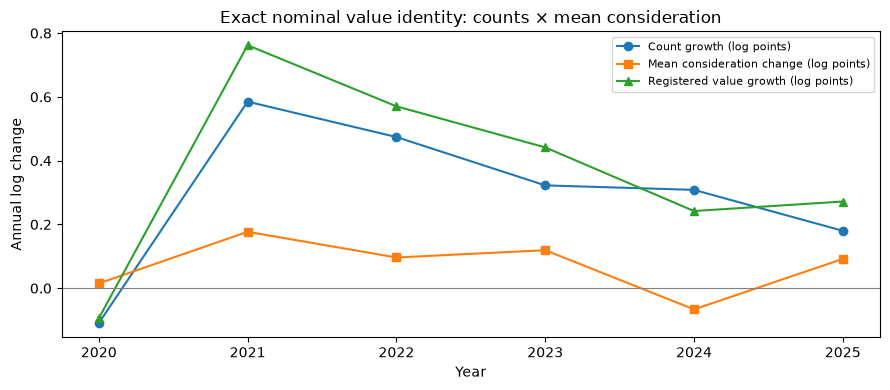

,year,transactions,registered_value_aed,mean_consideration_aed,delta_log_transactions,delta_log_registered_value_aed,delta_log_mean_consideration_aed,log_identity_residual,delta_n,delta_value_aed
11,2021,59424,148350178469,2.496469e+06,0.585104,0.762034,0.176930,-2.498002e-16,26322.0,7.911278e+10
12,2022,95471,262437530423,2.748872e+06,0.474124,0.570438,0.096313,1.526557e-16,36047.0,1.140874e+11
13,2023,131801,408152113488,3.096730e+06,0.322471,0.441627,0.119156,-4.163336e-17,36330.0,1.457146e+11
14,2024,179416,519915960524,2.897824e+06,0.308414,0.242027,-0.066387,1.387779e-17,47615.0,1.117638e+11
15,2025,214803,682330410397,3.176540e+06,0.180014,0.271847,0.091833,-8.326673e-17,35387.0,1.624144e+11


In [6]:
value_bridge=activity_annual[['year','transactions','registered_value_aed','mean_consideration_aed']].copy()
for col in ['transactions','registered_value_aed','mean_consideration_aed']:
    value_bridge['delta_log_'+col]=np.where((value_bridge[col]>0)&(value_bridge[col].shift()>0),np.log(value_bridge[col]/value_bridge[col].shift()),np.nan)
value_bridge['log_identity_residual']=(value_bridge.delta_log_registered_value_aed-value_bridge.delta_log_transactions-value_bridge.delta_log_mean_consideration_aed)
assert np.nanmax(np.abs(value_bridge.log_identity_residual.to_numpy()))<1e-10
value_bridge['delta_n']=value_bridge.transactions.diff()
value_bridge['delta_value_aed']=value_bridge.registered_value_aed.diff()
activity_count_value_bridge=value_bridge
fig,ax=plt.subplots(figsize=(9,4));z=value_bridge.query('year >= 2020').set_index('year')
ax.plot(z.index,z.delta_log_transactions,marker='o',label='Count growth (log points)')
ax.plot(z.index,z.delta_log_mean_consideration_aed,marker='s',label='Mean consideration change (log points)')
ax.plot(z.index,z.delta_log_registered_value_aed,marker='^',label='Registered value growth (log points)')
ax.axhline(0,color='gray',lw=.8);ax.set(title='Exact nominal value identity: counts × mean consideration',xlabel='Year',ylabel='Annual log change');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'03_count_value_bridge.png',dpi=150);plt.show()
display(value_bridge.tail())

In [7]:
g=q.loc[q.year.between(2021,2025)].copy()
recent=q.loc[q.year.between(2022,2025)].copy()
activity_momentum_summary=pd.DataFrame([dict(period='2022–2025 quarters',quarters=len(recent),positive_yoy_quarters=int((recent.yoy_pct>0).sum()),negative_yoy_quarters=int((recent.yoy_pct<0).sum()),median_yoy_pct=float(recent.yoy_pct.median()),yoy_std_pct=float(recent.yoy_pct.std()),positive_abs_delta_quarters=int((recent.yoy_delta_n>0).sum()),last_yoy_pct=float(recent.yoy_pct.iloc[-1]))])
print('Momentum diagnostics are observational; no cycle cause is inferred.')
display(activity_momentum_summary)

Momentum diagnostics are observational; no cycle cause is inferred.


,period,quarters,positive_yoy_quarters,negative_yoy_quarters,median_yoy_pct,yoy_std_pct,positive_abs_delta_quarters,last_yoy_pct
0,2022–2025 quarters,16,16,0,40.784294,18.218427,16,15.132549


## 12 — Registration mix and decomposition contract

**Classification:** `Ready`, `Off-Plan`, `Unknown` exhaust P0 registrations, including any unexpected or missing labels. Only total P0 registrations define the principal Off-Plan share. Gross registered values use the same partition. Ready is **not** automatically resale; Off-Plan is **not** a cashflow or speculation label.

Scale/share decomposition $\Delta O=\bar S\Delta N+\bar N\Delta S$ is an exact arithmetic identity. Property-composition decomposition of the Off-Plan share uses stable source property categories. If any category is absent in an endpoint, rates are undefined; any such category is explicitly allocated to an **entry/exit residual**, and the within/between terms are calculated only where both rates exist. Neither component is a causal treatment effect.

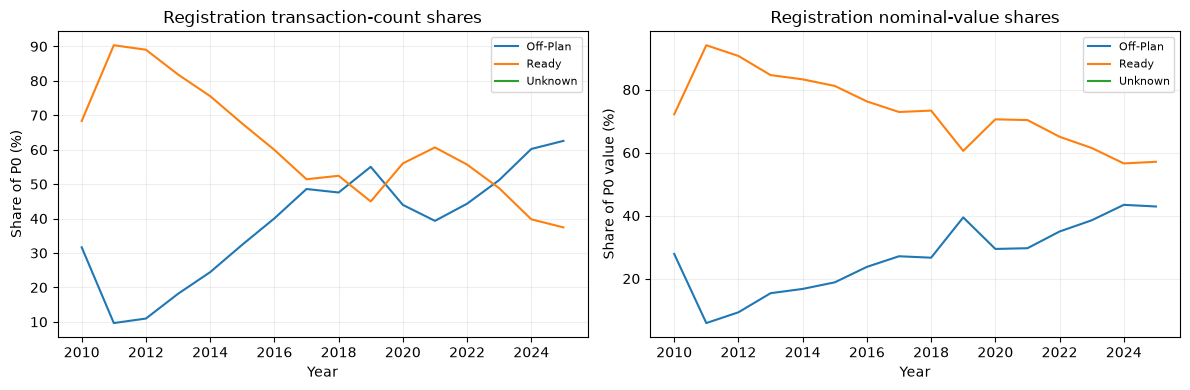

,year,reg,n,value_aed,transactions,registered_value_aed,count_share,value_share
22,2021,Off-Plan,23375,43988359513,59424,148350178469,0.393360,0.296517
23,2021,Ready,36049,104361818956,59424,148350178469,0.606640,0.703483
30,2025,Off-Plan,134384,292738825292,214803,682330410397,0.625615,0.429028
31,2025,Ready,80419,389591585105,214803,682330410397,0.374385,0.570972


In [8]:
registration_activity_panel=p0.groupby(['year','quarter','reg'],dropna=False,observed=True).agg(n=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index()
annual_registration=registration_activity_panel.groupby(['year','reg'],observed=True).agg(n=('n','sum'),value_aed=('value_aed','sum')).reset_index()
annual_registration=annual_registration.merge(activity_annual[['year','transactions','registered_value_aed']],on='year',how='left',validate='many_to_one')
annual_registration['count_share']=annual_registration.n/annual_registration.transactions
annual_registration['value_share']=np.where(annual_registration.registered_value_aed>0,annual_registration.value_aed/annual_registration.registered_value_aed,np.nan)
assert (annual_registration.groupby('year').n.sum().reindex(activity_annual.year).to_numpy()==activity_annual.transactions.to_numpy()).all()
assert np.allclose(annual_registration.groupby('year').value_aed.sum().reindex(activity_annual.year).to_numpy(),activity_annual.registered_value_aed.to_numpy())
fig,axes=plt.subplots(1,2,figsize=(12,4))
for reg in ['Off-Plan','Ready','Unknown']:
    a=annual_registration.query('reg==@reg')
    axes[0].plot(a.year,100*a.count_share,label=reg)
    axes[1].plot(a.year,100*a.value_share,label=reg)
axes[0].set(title='Registration transaction-count shares',ylabel='Share of P0 (%)',xlabel='Year')
axes[1].set(title='Registration nominal-value shares',ylabel='Share of P0 value (%)',xlabel='Year')
for ax in axes: ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(FIG/'03_registration_shares.png',dpi=150);plt.show()
display(annual_registration.query('year in [2021,2025]'))

year,reg,n0,n1,delta
0,Ready,36049,80419,44370
1,Off-Plan,23375,134384,111009
2,Unknown,0,0,0


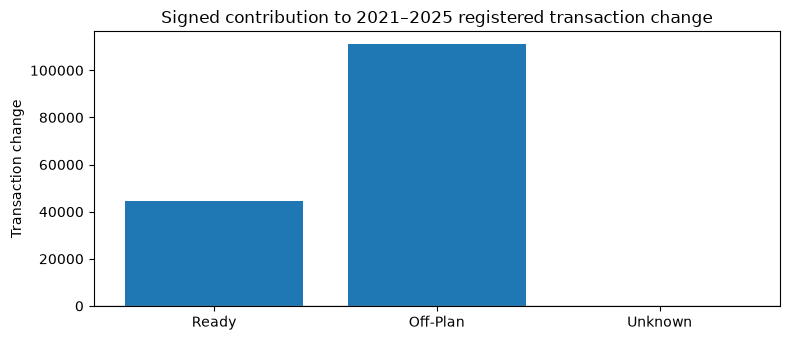

In [9]:
def registration_count_bridge(frame,start=2021,end=2025):
    tab=frame.loc[frame.year.isin([start,end])].groupby(['year','reg'],observed=True).size().unstack('year',fill_value=0).reindex(['Ready','Off-Plan','Unknown'],fill_value=0)
    for year in (start,end):
        if year not in tab.columns: tab[year]=0
    tab=tab.rename(columns={start:'n0',end:'n1'});tab['delta']=tab.n1-tab.n0
    assert int(tab.delta.sum())==int((frame.year==end).sum()-(frame.year==start).sum())
    return tab.reset_index()
registration_growth_contributions=registration_count_bridge(p0)
display(registration_growth_contributions)
fig,ax=plt.subplots(figsize=(8,3.5));ax.bar(registration_growth_contributions.reg,registration_growth_contributions.delta)
ax.axhline(0,color='gray',lw=1);ax.set(title='Signed contribution to 2021–2025 registered transaction change',ylabel='Transaction change');fig.tight_layout();fig.savefig(FIG/'03_registration_growth_contributions.png',dpi=150);plt.show()

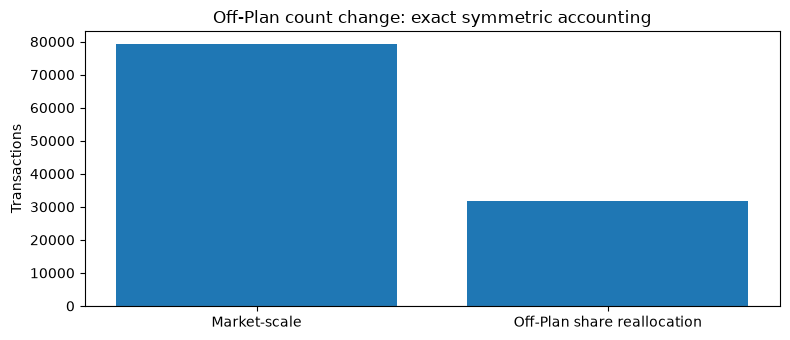

,start,end,n0,n1,offplan_n0,offplan_n1,offplan_share0,offplan_share1,delta_offplan,market_scale_component,share_reallocation_component,reconciliation_error
0,2021,2025,59424,214803,23375,134384,0.393360,0.625615,111009,79163.633700,31845.366300,1.455192e-11
1,2020,2025,33102,214803,14557,134384,0.439762,0.625615,119827,96790.037354,23036.962646,0.000000e+00


In [10]:
def offplan_scale_share(frame,start,end):
    z=frame.loc[frame.year.isin([start,end])]
    n0=int((z.year==start).sum());n1=int((z.year==end).sum())
    if min(n0,n1)==0: return None
    o0=int(((z.year==start)&z.reg.eq('Off-Plan')).sum());o1=int(((z.year==end)&z.reg.eq('Off-Plan')).sum())
    s0=o0/n0;s1=o1/n1
    scale=(n1-n0)*(s0+s1)/2
    reallocation=(s1-s0)*(n0+n1)/2
    assert np.isclose(scale+reallocation,o1-o0,rtol=0,atol=1e-8)
    return dict(start=start,end=end,n0=n0,n1=n1,offplan_n0=o0,offplan_n1=o1,offplan_share0=s0,offplan_share1=s1,delta_offplan=o1-o0,market_scale_component=scale,share_reallocation_component=reallocation,reconciliation_error=scale+reallocation-(o1-o0))
offplan_scale_share_decomposition=pd.DataFrame([r for a,b in [(2021,2025),(2020,2025)] if (r:=offplan_scale_share(p0,a,b)) is not None])
assert not offplan_scale_share_decomposition.empty
r=offplan_scale_share_decomposition.query('start==2021').iloc[0]
fig,ax=plt.subplots(figsize=(8,3.5));ax.bar(['Market-scale','Off-Plan share reallocation'],[r.market_scale_component,r.share_reallocation_component]);ax.axhline(0,color='gray',lw=.8);ax.set(title='Off-Plan count change: exact symmetric accounting',ylabel='Transactions');fig.tight_layout();fig.savefig(FIG/'03_offplan_scale_share_bridge.png',dpi=150);plt.show()
display(offplan_scale_share_decomposition)

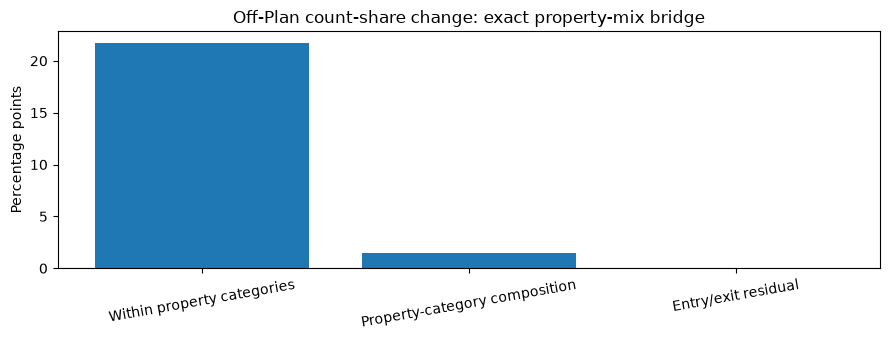

,ptype,n0,n1,offplan_n0,offplan_n1,w0,w1,r0,r1,within,composition,entry_exit_residual
0,Building,271,622,0,0,0.004560,0.002896,0.000000,0.000000,0.000000,-0.000000,0.0
1,Land,6208,21527,0,0,0.104470,0.100217,0.000000,0.000000,0.000000,-0.000000,0.0
2,Unit,40619,175643,18030,125090,0.683545,0.817693,0.443881,0.712183,0.201393,0.077542,0.0
3,Villa,12326,17011,5345,9294,0.207425,0.079193,0.433636,0.546352,0.016153,-0.062833,0.0


,start,end,offplan_share_delta,within_property_component,property_composition_component,entry_exit_residual,all_categories,continuing_categories,total_n0,total_n1
0,2021,2025,0.232256,0.217546,0.014709,0.0,4,4,59424,214803


In [11]:
# Use a stable, exhaustive grouping; distinguish undefined rates from zero off-plan participation.
def offplan_property_mix(frame,start,end):
    z=frame.loc[frame.year.isin([start,end])].copy()
    totals=z.groupby('year').size();n0=int(totals.get(start,0));n1=int(totals.get(end,0))
    if min(n0,n1)==0: return pd.DataFrame(),pd.DataFrame()
    tab=z.groupby(['ptype','year'],observed=True).agg(n=('transaction_id','size'),o=('reg',lambda s:int(s.eq('Off-Plan').sum()))).reset_index()
    both=sorted(tab.ptype.unique().tolist())
    data=[]
    for k in both:
        sub=tab[tab.ptype.eq(k)].set_index('year')
        c0=int(sub.loc[start,'n']) if start in sub.index else 0
        c1=int(sub.loc[end,'n']) if end in sub.index else 0
        o0=int(sub.loc[start,'o']) if start in sub.index else 0
        o1=int(sub.loc[end,'o']) if end in sub.index else 0
        w0=c0/n0;w1=c1/n1
        r0=o0/c0 if c0 else np.nan;r1=o1/c1 if c1 else np.nan
        if c0 and c1:
            within=(w0+w1)/2*(r1-r0)
            composition=(r0+r1)/2*(w1-w0)
            residual=0.
        else:
            within=0.;composition=0.;residual=w1*(r1 if np.isfinite(r1) else 0)-w0*(r0 if np.isfinite(r0) else 0)
        data.append(dict(ptype=k,n0=c0,n1=c1,offplan_n0=o0,offplan_n1=o1,w0=w0,w1=w1,r0=r0,r1=r1,within=within,composition=composition,entry_exit_residual=residual))
    detail=pd.DataFrame(data)
    delta_s=sum(detail.w1*detail.r1.fillna(0))-sum(detail.w0*detail.r0.fillna(0))
    assert np.isclose(detail[['within','composition','entry_exit_residual']].to_numpy().sum(),delta_s,atol=1e-12)
    summary=pd.DataFrame([dict(start=start,end=end,offplan_share_delta=delta_s,within_property_component=detail.within.sum(),property_composition_component=detail.composition.sum(),entry_exit_residual=detail.entry_exit_residual.sum(),all_categories=len(detail),continuing_categories=int(((detail.n0>0)&(detail.n1>0)).sum()),total_n0=n0,total_n1=n1)])
    return detail,summary
property_mix_detail,offplan_property_mix_decomposition=offplan_property_mix(p0,T0,T1)
assert not offplan_property_mix_decomposition.empty
row=offplan_property_mix_decomposition.iloc[0]
fig,ax=plt.subplots(figsize=(9,3.5));lab=['Within property categories','Property-category composition','Entry/exit residual'];val=[row.within_property_component,row.property_composition_component,row.entry_exit_residual]
ax.bar(lab,np.array(val)*100);ax.axhline(0,color='gray',lw=.8);ax.set(title='Off-Plan count-share change: exact property-mix bridge',ylabel='Percentage points');ax.tick_params(axis='x',labelrotation=10);fig.tight_layout();fig.savefig(FIG/'03_offplan_property_mix_bridge.png',dpi=150);plt.show()
display(property_mix_detail);display(offplan_property_mix_decomposition)

In [12]:
# Activity-cohort sensitivity, not a correction for missing residential information.
def reg_view(mask,label):
    d=engineered.loc[mask & historical,['year','reg_type_label','property_type_label','price_aed']].copy()
    d['year']=d.year.astype(int)
    d['reg']=d.reg_type_label.where(d.reg_type_label.isin(['Ready','Off-Plan']),'Unknown')
    def slice_view(part,segment):
        a=part[part.year.eq(T0)];b=part[part.year.eq(T1)]
        if min(len(a),len(b))==0: return None
        return dict(population=label,segment=segment,n_2021=len(a),n_2025=len(b),offplan_n_2021=int(a.reg.eq('Off-Plan').sum()),offplan_n_2025=int(b.reg.eq('Off-Plan').sum()),offplan_share_change_pp=100*(b.reg.eq('Off-Plan').mean()-a.reg.eq('Off-Plan').mean()),unknown_2021_pct=100*a.reg.eq('Unknown').mean(),unknown_2025_pct=100*b.reg.eq('Unknown').mean())
    rows=[]
    for segment,sub in [('All eligible',d),('Units',d.loc[d.property_type_label.eq('Unit')]),('Villas',d.loc[d.property_type_label.eq('Villa')])]:
        v=slice_view(sub,segment)
        if v is not None: rows.append(v)
    return rows
offplan_mix_sensitivity=pd.DataFrame(reg_view(p0_mask,'P0')+reg_view(p1_mask,'P1 Core')+reg_view(strict_mask,'P1 Strict'))
display(offplan_mix_sensitivity)
# Unknown is not dropped: both endpoints use the full category denominator.

,population,segment,n_2021,n_2025,offplan_n_2021,offplan_n_2025,offplan_share_change_pp,unknown_2021_pct,unknown_2025_pct
0,P0,All eligible,59424,214803,23375,134384,23.225551,0.0,0.0
1,P0,Units,40619,175643,18030,125090,26.830229,0.0,0.0
2,P0,Villas,12326,17011,5345,9294,11.271614,0.0,0.0
3,P1 Core,All eligible,46941,182395,22025,131102,24.957464,0.0,0.0
4,P1 Core,Units,35984,166495,16680,121808,26.806220,0.0,0.0
5,P1 Core,Villas,10957,15900,5345,9294,9.671229,0.0,0.0
6,P1 Strict,All eligible,46302,178962,21654,128562,25.070718,0.0,0.0
7,P1 Strict,Units,35546,163322,16417,119449,26.951891,0.0,0.0
8,P1 Strict,Villas,10756,15640,5237,9113,9.578160,0.0,0.0


## 18 — RQ05 interpretation gate

Arithmetic decompositions can support a **descriptive** statement about the observed share/count change when all identities reconcile. A sign reversal in Unit/Villa or cohort sensitivities forces an explicit qualification. If undefined categories are substantial, the residual is reported rather than assigning arbitrary 0% or 100% rates. No statement about construction completion, developer cash collection, price discovery, speculative intent or policy causes follows from these data.

## 19 — Property/usage structure and category denominators

Property type, usage and registration must reconcile to P0. Joint-category count/value contributions explain recorded transaction composition, not economic causation. Signed contribution shares can exceed 100% of net growth if other categories contract; always report absolute deltas alongside relative shares. The 2021 reference category universe is fixed before examining later growth.

In [13]:
activity_joint_segment_panel=(p0.groupby(['year','quarter','ptype','usage','reg'],observed=True,dropna=False).agg(transactions=('transaction_id','size'),registered_value_aed=('price_aed','sum')).reset_index())
assert int(activity_joint_segment_panel.transactions.sum())==len(p0)
assert np.isclose(activity_joint_segment_panel.registered_value_aed.sum(),p0.price_aed.sum())
joint_endpoint=(activity_joint_segment_panel.loc[activity_joint_segment_panel.year.isin([T0,T1])].groupby(['ptype','usage','reg','year'],observed=True)[['transactions','registered_value_aed']].sum().reset_index())
pivot=joint_endpoint.pivot_table(index=['ptype','usage','reg'],columns='year',values='transactions',fill_value=0,observed=True)
for year in [T0,T1]:
    if year not in pivot: pivot[year]=0
pivot['delta']=pivot[T1]-pivot[T0]
assert int(pivot.delta.sum())==int((p0.year==T1).sum()-(p0.year==T0).sum())
joint_growth_bridge=pivot.reset_index().sort_values('delta',ascending=False)
display(joint_growth_bridge.head(12))

year,ptype,usage,reg,2021,2025,delta
10,Unit,Residential,Off-Plan,16680.0,121808.0,105128.0
11,Unit,Residential,Ready,19304.0,44687.0,25383.0
4,Land,Other,Ready,996.0,9703.0,8707.0
5,Land,Residential,Ready,3240.0,8998.0,5758.0
14,Villa,Residential,Off-Plan,5345.0,9294.0,3949.0
6,Unit,Commercial,Off-Plan,67.0,2187.0,2120.0
7,Unit,Commercial,Ready,2264.0,3923.0,1659.0
15,Villa,Residential,Ready,5612.0,6606.0,994.0
9,Unit,Other,Ready,1021.0,1943.0,922.0
3,Land,Commercial,Ready,1972.0,2826.0,854.0


In [14]:
seg=p0.groupby(['year','ptype','usage','reg'],observed=True,dropna=False).agg(n=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index()
seg['mean_aed']=np.where(seg.n>0,seg.value_aed/seg.n,np.nan)
seg['year_count_share']=seg.n/seg.groupby('year').n.transform('sum')
seg['year_value_share']=seg.value_aed/seg.groupby('year').value_aed.transform('sum')
a=seg.loc[seg.year.eq(T0)].drop(columns='year').rename(columns={v:v+'_0' for v in ['n','value_aed','mean_aed','year_count_share','year_value_share']})
b=seg.loc[seg.year.eq(T1)].drop(columns='year').rename(columns={v:v+'_1' for v in ['n','value_aed','mean_aed','year_count_share','year_value_share']})
activity_segment_count_value_divergence=a.merge(b,on=['ptype','usage','reg'],how='outer').fillna({'n_0':0,'n_1':0,'value_aed_0':0,'value_aed_1':0})
d=activity_segment_count_value_divergence
d['count_delta']=d.n_1-d.n_0;d['value_delta_aed']=d.value_aed_1-d.value_aed_0
d['count_growth_pct']=np.where(d.n_0>0,100*d.count_delta/d.n_0,np.nan)
d['value_growth_pct']=np.where(d.value_aed_0>0,100*d.value_delta_aed/d.value_aed_0,np.nan)
d['count_share_delta_pp']=100*(d.year_count_share_1.fillna(0)-d.year_count_share_0.fillna(0))
d['value_share_delta_pp']=100*(d.year_value_share_1.fillna(0)-d.year_value_share_0.fillna(0))
assert np.isclose(d.value_delta_aed.sum(),p0.loc[p0.year.eq(T1),'price_aed'].sum()-p0.loc[p0.year.eq(T0),'price_aed'].sum())
display(d.sort_values('value_delta_aed',ascending=False).head(10))

,ptype,usage,reg,n_0,value_aed_0,mean_aed_0,year_count_share_0,year_value_share_0,n_1,value_aed_1,mean_aed_1,year_count_share_1,year_value_share_1,count_delta,value_delta_aed,count_growth_pct,value_growth_pct,count_share_delta_pp,value_share_delta_pp
10,Unit,Residential,Off-Plan,16680,31210449454,1.871130e+06,0.280695,0.210384,121808,245684070336,2.016978e+06,0.567068,0.360066,105128,214473620882,630.263789,687.185301,28.637376,14.968250
4,Land,Other,Ready,996,8193296196,8.226201e+06,0.016761,0.055229,9703,84519580878,8.710665e+06,0.045172,0.123869,8707,76326284682,874.196787,931.569943,2.841072,6.863956
3,Land,Commercial,Ready,1972,11756949929,5.961942e+06,0.033185,0.079251,2826,68759261655,2.433095e+07,0.013156,0.100771,854,57002311726,43.306288,484.839283,-2.002900,2.151987
5,Land,Residential,Ready,3240,18897009250,5.832410e+06,0.054523,0.127381,8998,68925298722,7.660069e+06,0.041890,0.101015,5758,50028289472,177.716049,264.741837,-1.263388,-2.636655
11,Unit,Residential,Ready,19304,27522028512,1.425716e+06,0.324852,0.185521,44687,76039965639,1.701613e+06,0.208037,0.111442,25383,48517937127,131.490883,176.287649,-11.681478,-7.407914
14,Villa,Residential,Off-Plan,5345,9884325411,1.849266e+06,0.089947,0.066628,9294,37682399980,4.054487e+06,0.043268,0.055226,3949,27798074569,73.882133,281.233907,-4.667927,-1.140230
15,Villa,Residential,Ready,5612,18053753453,3.216991e+06,0.094440,0.121697,6606,33381683330,5.053237e+06,0.030754,0.048923,994,15327929877,17.712046,84.901624,-6.368620,-7.277383
0,Building,Commercial,Ready,161,1900361234,1.180349e+07,0.002709,0.012810,379,12471242267,3.290565e+07,0.001764,0.018277,218,10570881033,135.403727,556.256402,-0.094494,0.546745
7,Unit,Commercial,Ready,2264,2516364366,1.111468e+06,0.038099,0.016962,3923,10310135392,2.628125e+06,0.018263,0.015110,1659,7793771026,73.277385,309.723470,-1.983584,-0.185215
6,Unit,Commercial,Off-Plan,67,151713040,2.264374e+06,0.001127,0.001023,2187,7703032660,3.522191e+06,0.010181,0.011289,2120,7551319620,3164.179104,4977.370185,0.905393,1.026663


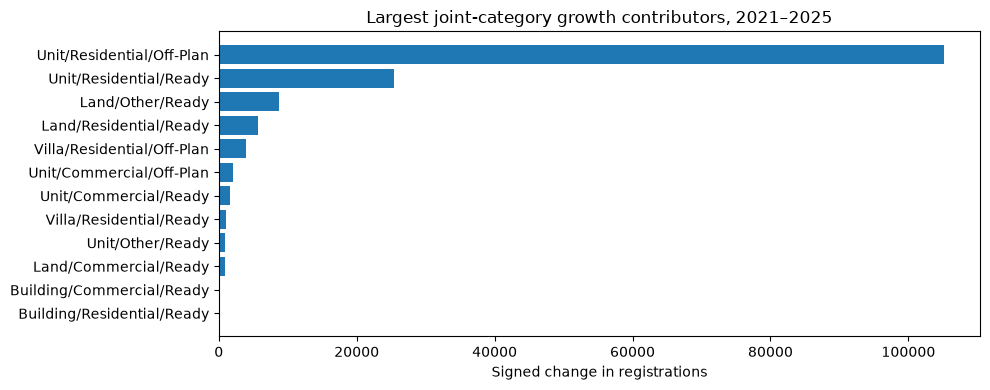

,total_segments,expanding_segments,contracting_segments,zero_segments,sum_positive_contributions,sum_negative_contributions,net_delta,top5_positive_growth_fraction
0,16,13,3,0,155825,-446,155379,0.95572


In [15]:
d=activity_segment_count_value_divergence.copy()
positive_total=d.loc[d.count_delta>0,'count_delta'].sum()
negative_total=d.loc[d.count_delta<0,'count_delta'].sum()
net_delta=d.count_delta.sum()
activity_segment_participation=pd.DataFrame([dict(total_segments=len(d),expanding_segments=int((d.count_delta>0).sum()),contracting_segments=int((d.count_delta<0).sum()),zero_segments=int((d.count_delta==0).sum()),sum_positive_contributions=int(positive_total),sum_negative_contributions=int(negative_total),net_delta=int(net_delta),top5_positive_growth_fraction=float(d.loc[d.count_delta>0,'count_delta'].nlargest(5).sum()/positive_total) if positive_total>0 else np.nan)])
assert positive_total+negative_total==net_delta
fig,ax=plt.subplots(figsize=(10,4));j=d.sort_values('count_delta',ascending=False).head(12).copy();j['label']=j.ptype+'/'+j.usage+'/'+j.reg
ax.barh(j.label.iloc[::-1],j.count_delta.iloc[::-1]);ax.set(xlabel='Signed change in registrations',title='Largest joint-category growth contributors, 2021–2025');fig.tight_layout();fig.savefig(FIG/'03_segment_contributions.png',dpi=150);plt.show()
display(activity_segment_participation)

In [16]:
# Provenance diagnostics: observed procedure mapping, not inferred economic transaction intent.
proc=p0.assign(procedure_known=p0.procedure_id.notna(),procedure_label_known=p0.procedure_name_en.notna())
registration_procedure_diagnostics=proc.groupby(['year','reg'],observed=True).agg(n=('transaction_id','size'),procedure_id_known=('procedure_known','sum'),procedure_label_known=('procedure_label_known','sum'),pre_registration_known=('is_pre_registration',lambda s:int(s.notna().sum())),distinct_procedures=('procedure_id','nunique')).reset_index()
for c in ['procedure_id_known','procedure_label_known','pre_registration_known']:
    registration_procedure_diagnostics[c+'_pct']=100*registration_procedure_diagnostics[c]/registration_procedure_diagnostics.n
procedure_crosswalk=(proc.groupby(['reg','procedure_id','procedure_name_en'],dropna=False,observed=True).size().rename('n').reset_index().sort_values('n',ascending=False))
# Identify source-code definitions used in multiple registration categories, if any.
procedure_registration_overlap=(proc.dropna(subset=['procedure_id']).groupby('procedure_id').reg.nunique().rename('distinct_registrations').reset_index())
print('Procedure codes with more than one registration category:',int((procedure_registration_overlap.distinct_registrations>1).sum()))
display(registration_procedure_diagnostics.tail(10));display(procedure_crosswalk.head(10))

Procedure codes with more than one registration category: 0


,year,reg,n,procedure_id_known,procedure_label_known,pre_registration_known,distinct_procedures,procedure_id_known_pct,procedure_label_known_pct,pre_registration_known_pct
22,2021,Off-Plan,23375,23375,23375,23375,3,100.0,100.0,100.0
23,2021,Ready,36049,36049,36049,36049,13,100.0,100.0,100.0
24,2022,Off-Plan,42312,42312,42312,42312,3,100.0,100.0,100.0
25,2022,Ready,53159,53159,53159,53159,12,100.0,100.0,100.0
26,2023,Off-Plan,67452,67452,67452,67452,3,100.0,100.0,100.0
27,2023,Ready,64349,64349,64349,64349,12,100.0,100.0,100.0
28,2024,Off-Plan,108033,108033,108033,108033,4,100.0,100.0,100.0
29,2024,Ready,71383,71383,71383,71383,12,100.0,100.0,100.0
30,2025,Off-Plan,134384,134384,134384,134384,4,100.0,100.0,100.0
31,2025,Ready,80419,80419,80419,80419,12,100.0,100.0,100.0


,reg,procedure_id,procedure_name_en,n
0,Off-Plan,102.0,Sell - Pre registration,516689
5,Ready,11.0,Sell,417670
6,Ready,41.0,Delayed Sell,142918
10,Ready,110.0,Lease to Own Registration,21925
7,Ready,45.0,Sell Development,12120
11,Ready,133.0,Development Registration,11832
2,Off-Plan,851.0,Development Registration Pre-Registration,4104
15,Ready,460.0,Sale On Payment Plan,2106
9,Ready,95.0,Delayed Development,1268
1,Off-Plan,107.0,Lease to Own Registration Pre-Registration,1116


## 24 — Property-structure conclusion policy

All joint category contributions reconcile to observed P0. Changes in count-weighted and consideration-weighted market structure may diverge because transaction-value distributions and category composition differ. Zero baseline counts make growth percentages undefined; absolute signed changes remain valid. Registration procedure diagnostics are source-quality evidence only and are not a surrogate for a developer/resale classification.

## 25 — Geography and breadth: fixed measurement contract

Use `area_id` as the canonical area identifier and `area_name_en` for display only. Treat absent identifiers as **Unknown geography**, not a fabricated community. Count/value HHI are conditioned on known geography; they are not housing-stock turnover, liquidity or neighborhood quality. Compare (i) each year's changing active-area universe, (ii) **common 2021–2025 areas** with renormalized weights and explicit coverage, and (iii) the 2021 fixed area universe. A community first observed in 2025 is an **observed entrant**, not proof of newly built supply.

In [17]:
community_activity_panel=(p0.loc[p0.area_known].groupby(['year','quarter','area_key'],observed=True).agg(transactions=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index())
community_annual=community_activity_panel.groupby(['year','area_key'],observed=True)[['transactions','value_aed']].sum().reset_index()
unknown_geography=p0.loc[~p0.area_known].groupby('year',observed=True).agg(unknown_n=('transaction_id','size'),unknown_value_aed=('price_aed','sum')).reindex(range(START_YEAR,END_YEAR+1),fill_value=0).reset_index()
known_counts=community_annual.groupby('year').transactions.sum().reindex(activity_annual.year,fill_value=0)
assert (known_counts.to_numpy()+unknown_geography.set_index('year').loc[activity_annual.year,'unknown_n'].to_numpy()==activity_annual.transactions.to_numpy()).all()
known_value=community_annual.groupby('year').value_aed.sum().reindex(activity_annual.year,fill_value=0)
assert np.allclose(known_value.to_numpy()+unknown_geography.set_index('year').loc[activity_annual.year,'unknown_value_aed'].to_numpy(),activity_annual.registered_value_aed.to_numpy())
name_conflicts=(p0.loc[p0.area_known].groupby('area_key').area_name_en.nunique(dropna=True).rename('distinct_names').reset_index())
print('Area IDs with multiple observed names:',int((name_conflicts.distinct_names>1).sum()))
display(community_annual.head(4))

Area IDs with multiple observed names: 0


,year,area_key,transactions,value_aed
0,2010,230.0,13,23173996
1,2010,231.0,3,99305552
2,2010,232.0,54,190715128
3,2010,233.0,48,106663100


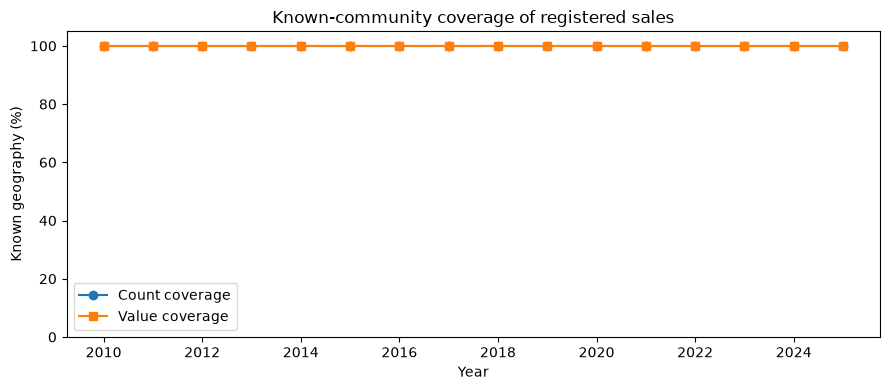

,year,transactions,registered_value_aed,unknown_n,unknown_value_aed,known_geography_n,known_geography_value_aed,known_geography_count_pct,known_geography_value_pct
10,2020,33102,69237399748,0,0,33102,69237399748,100.0,100.0
11,2021,59424,148350178469,0,0,59424,148350178469,100.0,100.0
12,2022,95471,262437530423,0,0,95471,262437530423,100.0,100.0
13,2023,131801,408152113488,0,0,131801,408152113488,100.0,100.0
14,2024,179416,519915960524,0,0,179416,519915960524,100.0,100.0
15,2025,214803,682330410397,0,0,214803,682330410397,100.0,100.0


In [18]:
coverage=activity_annual[['year','transactions','registered_value_aed']].merge(unknown_geography,on='year',how='left')
coverage['known_geography_n']=coverage.transactions-coverage.unknown_n
coverage['known_geography_value_aed']=coverage.registered_value_aed-coverage.unknown_value_aed
coverage['known_geography_count_pct']=100*coverage.known_geography_n/coverage.transactions
coverage['known_geography_value_pct']=np.where(coverage.registered_value_aed>0,100*coverage.known_geography_value_aed/coverage.registered_value_aed,np.nan)
activity_geography_coverage=coverage
fig,ax=plt.subplots(figsize=(9,4));ax.plot(coverage.year,coverage.known_geography_count_pct,marker='o',label='Count coverage');ax.plot(coverage.year,coverage.known_geography_value_pct,marker='s',label='Value coverage');ax.set(title='Known-community coverage of registered sales',xlabel='Year',ylabel='Known geography (%)',ylim=(0,105));ax.legend();fig.tight_layout();fig.savefig(FIG/'03_geography_coverage.png',dpi=150);plt.show()
display(coverage.tail(6))

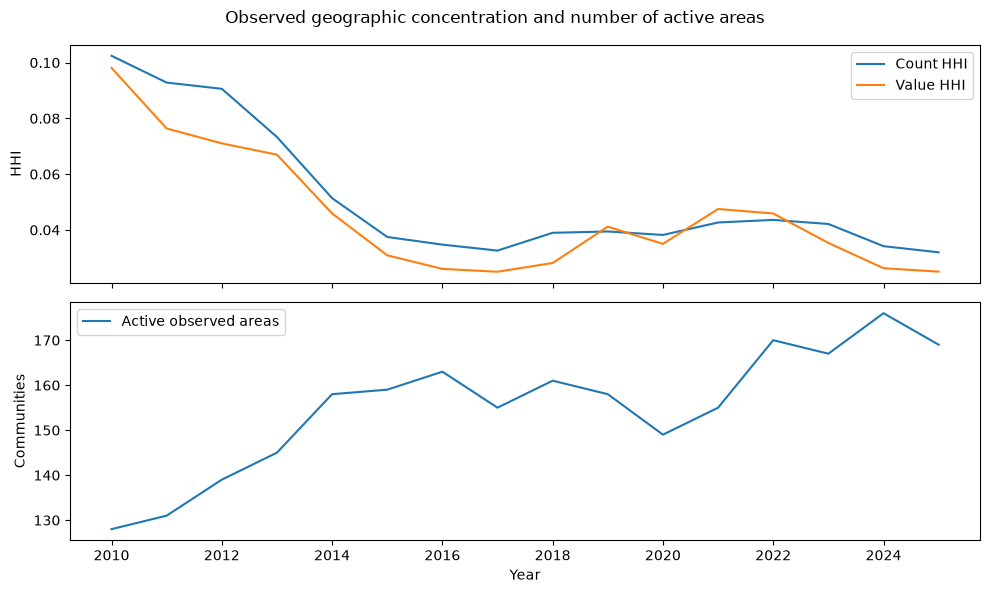

,year,active_communities,count_hhi,value_hhi,count_effective,value_effective,top5_count_share,top10_count_share,top5_value_share,top10_value_share
11,2021,155,0.042678,0.047509,23.431499,21.048773,0.358508,0.580456,0.411524,0.588763
15,2025,169,0.031983,0.025058,31.266434,39.906815,0.284973,0.445306,0.209137,0.377866


In [19]:
def concentration_stats(detail, count_col='transactions',value_col='value_aed'):
    n=detail[count_col].astype(float);v=detail[value_col].astype(float)
    if not len(detail) or n.sum()<=0: return dict(active_communities=0,count_hhi=np.nan,value_hhi=np.nan,count_effective=np.nan,value_effective=np.nan,top5_count_share=np.nan,top10_count_share=np.nan,top5_value_share=np.nan,top10_value_share=np.nan)
    sn=n/n.sum();sv=v/v.sum() if v.sum()>0 else pd.Series(np.nan,index=v.index)
    hhi=float((sn**2).sum());vh=float((sv**2).sum()) if v.sum()>0 else np.nan
    return dict(active_communities=int((n>0).sum()),count_hhi=hhi,value_hhi=vh,count_effective=1/hhi,value_effective=1/vh if vh>0 else np.nan,top5_count_share=float(sn.nlargest(5).sum()),top10_count_share=float(sn.nlargest(10).sum()),top5_value_share=float(sv.nlargest(5).sum()) if v.sum()>0 else np.nan,top10_value_share=float(sv.nlargest(10).sum()) if v.sum()>0 else np.nan)
community_concentration_yearly=pd.DataFrame([dict(year=int(year),**concentration_stats(d)) for year,d in community_annual.groupby('year')])
assert community_concentration_yearly.count_hhi.between(0,1).all()
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True);axes[0].plot(community_concentration_yearly.year,community_concentration_yearly.count_hhi,label='Count HHI');axes[0].plot(community_concentration_yearly.year,community_concentration_yearly.value_hhi,label='Value HHI');axes[0].legend()
axes[1].plot(community_concentration_yearly.year,community_concentration_yearly.active_communities,label='Active observed areas');axes[1].set_ylabel('Communities');axes[0].set_ylabel('HHI');axes[1].set_xlabel('Year');axes[1].legend()
fig.suptitle('Observed geographic concentration and number of active areas');fig.tight_layout();fig.savefig(FIG/'03_geographic_concentration.png',dpi=150);plt.show()
display(community_concentration_yearly.query('year in [2021,2025]'))

In [20]:
base_ids=set(community_annual.loc[community_annual.year.eq(T0),'area_key']);end_ids=set(community_annual.loc[community_annual.year.eq(T1),'area_key'])
common_ids=base_ids & end_ids;entrant_ids=end_ids-base_ids;exit_ids=base_ids-end_ids
universe_rows=[]
for label,ids in [('all_known',None),('common_2021_2025',common_ids),('fixed_2021',base_ids)]:
    for year in (T0,T1):
        full=community_annual[community_annual.year.eq(year)]
        sub=full if ids is None else full[full.area_key.isin(ids)]
        v=concentration_stats(sub)
        universe_rows.append(dict(universe=label,year=year,area_universe_n=len(ids) if ids is not None else int(full.area_key.nunique()),population_n=int(p0.year.eq(year).sum()),known_n=int(full.transactions.sum()),included_n=int(sub.transactions.sum()),coverage_p0_pct=100*sub.transactions.sum()/max(1,int(p0.year.eq(year).sum())),coverage_known_pct=100*sub.transactions.sum()/max(1,int(full.transactions.sum())),**v))
community_universe_sensitivity=pd.DataFrame(universe_rows)
assert len(common_ids)<=min(len(base_ids),len(end_ids))
assert (community_universe_sensitivity.coverage_p0_pct<=100+1e-10).all()
print('2021 / 2025 community universe: common',len(common_ids),'observed entrants',len(entrant_ids),'observed exits',len(exit_ids))
display(community_universe_sensitivity)

2021 / 2025 community universe: common 147 observed entrants 22 observed exits 8


,universe,year,area_universe_n,population_n,known_n,included_n,coverage_p0_pct,coverage_known_pct,active_communities,count_hhi,value_hhi,count_effective,value_effective,top5_count_share,top10_count_share,top5_value_share,top10_value_share
0,all_known,2021,155,59424,59424,59424,100.000000,100.000000,155,0.042678,0.047509,23.431499,21.048773,0.358508,0.580456,0.411524,0.588763
1,all_known,2025,169,214803,214803,214803,100.000000,100.000000,169,0.031983,0.025058,31.266434,39.906815,0.284973,0.445306,0.209137,0.377866
2,common_2021_2025,2021,147,59424,59424,58436,98.337372,98.337372,147,0.043992,0.048301,22.731257,20.703618,0.364570,0.590270,0.415078,0.593847
3,common_2021_2025,2025,147,214803,214803,207924,96.797531,96.797531,147,0.033605,0.027403,29.757545,36.492731,0.294401,0.460038,0.227509,0.411060
4,fixed_2021,2021,155,59424,59424,59424,100.000000,100.000000,155,0.042678,0.047509,23.431499,21.048773,0.358508,0.580456,0.411524,0.588763
5,fixed_2021,2025,155,214803,214803,207924,96.797531,96.797531,147,0.033605,0.027403,29.757545,36.492731,0.294401,0.460038,0.227509,0.411060


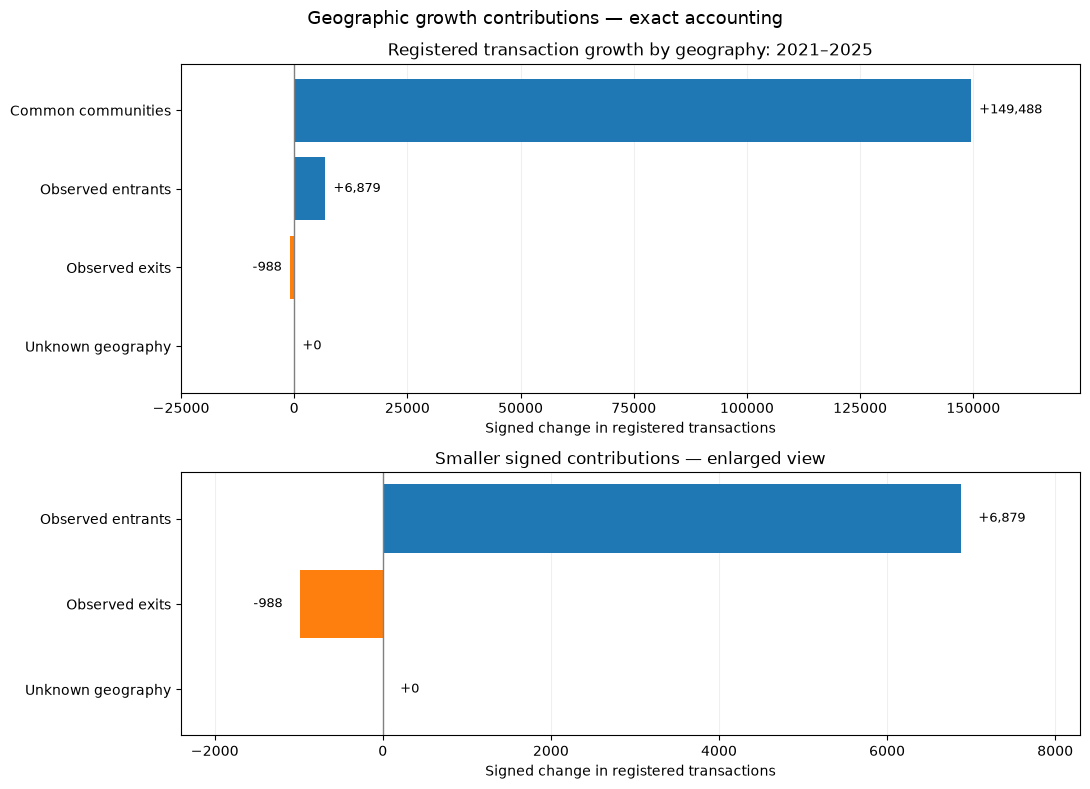

,metric,common_community_delta,observed_entrants,observed_exits,unknown_geography_delta,observed_total_delta,reconciliation_error
0,transactions,1.494880e+05,6.879000e+03,-9.880000e+02,0.0,1.553790e+05,0.0
1,registered_value_aed,4.801511e+11,5.509917e+10,-1.270077e+09,0.0,5.339802e+11,0.0


,component,signed_change_transactions
0,Common communities,149488.0
1,Observed entrants,6879.0
2,Observed exits,-988.0
3,Unknown geography,0.0


Geographic count-growth reconciliation: 155,379 = 155,379
Observed entrants/exits refer to source-area appearances, not proven physical development or community construction.


In [21]:

# ============================================================
# CELL 30 — Exact Geographic Growth Accounting
# ============================================================

c0 = community_annual.loc[
    community_annual["year"].eq(T0)
].set_index("area_key")

c1 = community_annual.loc[
    community_annual["year"].eq(T1)
].set_index("area_key")


def area_sum(frame, area_ids, field):
    return float(
        frame.loc[
            frame.index.isin(area_ids), field
        ].sum()
    )


unknown_by_year = unknown_geography.set_index("year")

components = []

for metric, field, unknown_field in [
    ("transactions", "transactions", "unknown_n"),
    (
        "registered_value_aed",
        "value_aed",
        "unknown_value_aed"
    )
]:

    # Growth in communities observed in both endpoints.
    common_delta = (
        area_sum(c1, common_ids, field)
        - area_sum(c0, common_ids, field)
    )

    # First-observed endpoint communities.
    entrant_contribution = area_sum(
        c1, entrant_ids, field
    )

    # Communities no longer observed at the endpoint.
    exit_contribution = -area_sum(
        c0, exit_ids, field
    )

    # Missing geographic identifiers remain explicit.
    unknown_delta = float(
        unknown_by_year.loc[T1, unknown_field]
        - unknown_by_year.loc[T0, unknown_field]
    )

    if metric == "transactions":
        observed_delta = float(
            p0["year"].eq(T1).sum()
            - p0["year"].eq(T0).sum()
        )
    else:
        observed_delta = float(
            p0.loc[
                p0["year"].eq(T1), "price_aed"
            ].sum()
            - p0.loc[
                p0["year"].eq(T0), "price_aed"
            ].sum()
        )

    reconstructed_delta = (
        common_delta
        + entrant_contribution
        + exit_contribution
        + unknown_delta
    )

    reconciliation_error = (
        reconstructed_delta - observed_delta
    )

    assert np.isclose(
        reconstructed_delta,
        observed_delta,
        atol=1e-5,
        rtol=1e-12
    ), (
        f"Geographic reconciliation failed: {metric}"
    )

    components.append({
        "metric": metric,
        "common_community_delta": common_delta,
        "observed_entrants": entrant_contribution,
        "observed_exits": exit_contribution,
        "unknown_geography_delta": unknown_delta,
        "observed_total_delta": observed_delta,
        "reconciliation_error": reconciliation_error
    })


community_activity_growth_bridge = pd.DataFrame(
    components
)

# ============================================================
# Improved visualization:
# Full-scale contributions plus a separate detail panel
# for the smaller components.
# ============================================================

r = community_activity_growth_bridge.loc[
    community_activity_growth_bridge[
        "metric"
    ].eq("transactions")
].iloc[0]

labels = [
    "Common communities",
    "Observed entrants",
    "Observed exits",
    "Unknown geography"
]

values = np.array([
    r["common_community_delta"],
    r["observed_entrants"],
    r["observed_exits"],
    r["unknown_geography_delta"]
], dtype=float)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    height_ratios=[1.25, 1]
)

# Main chart: all exact signed components.
colors = [
    "tab:blue" if value >= 0 else "tab:orange"
    for value in values
]

bars = axes[0].barh(
    labels,
    values,
    color=colors
)

axes[0].axvline(
    0, color="gray", linewidth=1
)

axes[0].invert_yaxis()

axes[0].set_title(
    f"Registered transaction growth by geography: {T0}–{T1}"
)

axes[0].set_xlabel(
    "Signed change in registered transactions"
)

axes[0].grid(
    axis="x", alpha=0.2
)

axes[0].set_axisbelow(True)

# Annotate components directly.
offset = max(np.max(np.abs(values)) * 0.012, 10)

for bar, value in zip(bars, values):
    axes[0].text(
        value + (
            offset if value >= 0 else -offset
        ),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+,.0f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

axes[0].margins(x=0.16)

# Detail chart: remove only the largest component
# to make smaller signed contributions visible.
largest_idx = int(
    np.argmax(np.abs(values))
)

detail_idx = [
    idx for idx in range(len(values))
    if idx != largest_idx
]

detail_values = values[detail_idx]
detail_labels = [
    labels[idx] for idx in detail_idx
]

detail_colors = [
    "tab:blue" if value >= 0 else "tab:orange"
    for value in detail_values
]

detail_bars = axes[1].barh(
    detail_labels,
    detail_values,
    color=detail_colors
)

axes[1].axvline(
    0, color="gray", linewidth=1
)

axes[1].invert_yaxis()

axes[1].set_title(
    "Smaller signed contributions — enlarged view"
)

axes[1].set_xlabel(
    "Signed change in registered transactions"
)

axes[1].grid(
    axis="x", alpha=0.2
)

axes[1].set_axisbelow(True)

detail_offset = max(
    np.max(np.abs(detail_values)) * 0.03, 5
)

for bar, value in zip(
    detail_bars, detail_values
):
    axes[1].text(
        value + (
            detail_offset if value >= 0
            else -detail_offset
        ),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+,.0f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

axes[1].margins(x=0.18)

fig.suptitle(
    "Geographic growth contributions — exact accounting",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    FIG / "03_geographic_growth_bridge.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Display the original research table unchanged.
display(
    community_activity_growth_bridge
)

# Additional readable count-only contribution table.
contribution_table = pd.DataFrame({
    "component": labels,
    "signed_change_transactions": values
})

display(contribution_table)

print(
    "Geographic count-growth reconciliation:",
    f"{values.sum():,.0f}",
    "=",
    f"{r['observed_total_delta']:,.0f}"
)

print(
    "Observed entrants/exits refer to source-area "
    "appearances, not proven physical development "
    "or community construction."
)


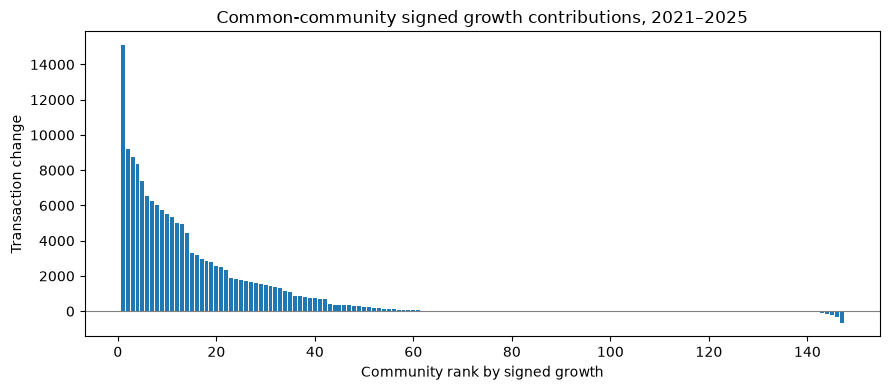

,universe,common_communities,expanding,contracting,unchanged,fraction_expanding,median_abs_change,total_positive_growth,total_negative_growth,top5_fraction_of_positive,top10_fraction_of_positive
0,Common 2021/2025 areas,147,122,21,4,0.829932,17.0,151055,-1567,0.32279,0.52173


,min_2021_n,areas,share_common_2021_n,expanding_fraction,top5_positive_fraction
0,1,147,1.000000,0.829932,0.322790
1,10,91,0.995842,0.879121,0.355249
2,30,63,0.988500,0.873016,0.360039
3,100,52,0.979191,0.846154,0.377898
4,300,38,0.935810,0.842105,0.434310


In [22]:
common_panel=(c0.loc[c0.index.isin(common_ids),['transactions']].rename(columns={'transactions':'n0'}).join(c1[['transactions']].rename(columns={'transactions':'n1'}),how='inner'))
common_panel['delta']=common_panel.n1-common_panel.n0
p_pos=common_panel.loc[common_panel.delta>0,'delta'].sum()
count_growth_breadth=pd.DataFrame([dict(universe='Common 2021/2025 areas',common_communities=len(common_panel),expanding=int((common_panel.delta>0).sum()),contracting=int((common_panel.delta<0).sum()),unchanged=int((common_panel.delta==0).sum()),fraction_expanding=float((common_panel.delta>0).mean()) if len(common_panel) else np.nan,median_abs_change=float(common_panel.delta.median()),total_positive_growth=int(p_pos),total_negative_growth=int(common_panel.loc[common_panel.delta<0,'delta'].sum()),top5_fraction_of_positive=float(common_panel.loc[common_panel.delta>0,'delta'].nlargest(5).sum()/p_pos) if p_pos>0 else np.nan,top10_fraction_of_positive=float(common_panel.loc[common_panel.delta>0,'delta'].nlargest(10).sum()/p_pos) if p_pos>0 else np.nan)])
# Base-count support sensitivity does not alter the reported full common-universe accounting.
base_thresholds=[1,10,30,100,300]
threshold_rows=[]
for threshold in base_thresholds:
    sub=common_panel.loc[common_panel.n0>=threshold]
    threshold_rows.append(dict(min_2021_n=threshold,areas=len(sub),share_common_2021_n=sub.n0.sum()/max(1,common_panel.n0.sum()),expanding_fraction=float((sub.delta>0).mean()) if len(sub) else np.nan,top5_positive_fraction=float(sub.loc[sub.delta>0,'delta'].nlargest(5).sum()/sub.loc[sub.delta>0,'delta'].sum()) if (sub.delta>0).any() else np.nan))
community_growth_threshold_sensitivity=pd.DataFrame(threshold_rows)
assert int(common_panel.delta.sum())==int(community_activity_growth_bridge.query("metric=='transactions'").iloc[0].common_community_delta)
fig,ax=plt.subplots(figsize=(9,4));ordered=common_panel.delta.sort_values(ascending=False);rank=np.arange(1,len(ordered)+1)
ax.bar(rank,ordered);ax.axhline(0,color='gray',lw=.8);ax.set(title='Common-community signed growth contributions, 2021–2025',xlabel='Community rank by signed growth',ylabel='Transaction change');fig.tight_layout();fig.savefig(FIG/'03_geographic_breadth.png',dpi=150);plt.show()
display(count_growth_breadth);display(community_growth_threshold_sensitivity)

In [23]:
# Additional new diagnostic: persistence of community-level YoY growth with strict same-quarter availability.
ca=community_activity_panel.sort_values(['area_key','year','quarter']).copy()
ca['prev_year']=ca.groupby(['area_key','quarter']).year.shift()
ca['prev_n']=ca.groupby(['area_key','quarter']).transactions.shift()
ca['yoy_delta']=np.where(ca.year-ca.prev_year==1,ca.transactions-ca.prev_n,np.nan)
ca['yoy_pct']=np.where((ca.year-ca.prev_year==1)&(ca.prev_n>0),100*(ca.transactions/ca.prev_n-1),np.nan)
# In 2022-25 test persistence over successive *annual* same-quarter observations.
ca['prev_yoy_delta']=ca.groupby(['area_key','quarter']).yoy_delta.shift()
ca['prev_yoy_year']=ca.groupby(['area_key','quarter']).year.shift()
valid=(ca.year.between(2023,2025)&ca.yoy_delta.notna()&ca.prev_yoy_delta.notna()&(ca.year-ca.prev_yoy_year==1))
cc=ca.loc[valid].copy()
cc['persistent_expansion']=(cc.yoy_delta>0)&(cc.prev_yoy_delta>0)
community_growth_persistence=(cc.groupby('year').agg(area_quarter_comparisons=('area_key','size'),persistent_expansion_pct=('persistent_expansion',lambda s:100*s.mean()),current_expansion_pct=('yoy_delta',lambda s:100*(s>0).mean()),median_area_quarter_delta=('yoy_delta','median')).reset_index())
print('Persistence compares the same community and quarter across three successive years; it is not an independent-unit estimate.')
display(community_growth_persistence)

Persistence compares the same community and quarter across three successive years; it is not an independent-unit estimate.


,year,area_quarter_comparisons,persistent_expansion_pct,current_expansion_pct,median_area_quarter_delta
0,2023,443,32.054176,61.625282,3.0
1,2024,461,33.188720,59.436009,2.0
2,2025,481,31.600832,54.054054,1.0


## 33 — Historical seasonality and regime diagnostics

Calendar days, administrative working days, local holidays, registration-timing lags and changes in category share are distinct mechanisms. The source only supports *observed calendar-time registration patterns*. Compare unadjusted monthly counts with a calendar-day rate and **within-year month shares**, not an inferred transaction-day schedule. The history has just 16 full years and sparse early years: model-selected structural breaks or economic-cycle explanations would be prone to overfitting. Use sustained same-quarter changes and transparent period comparisons; label all regime boundaries as descriptive.

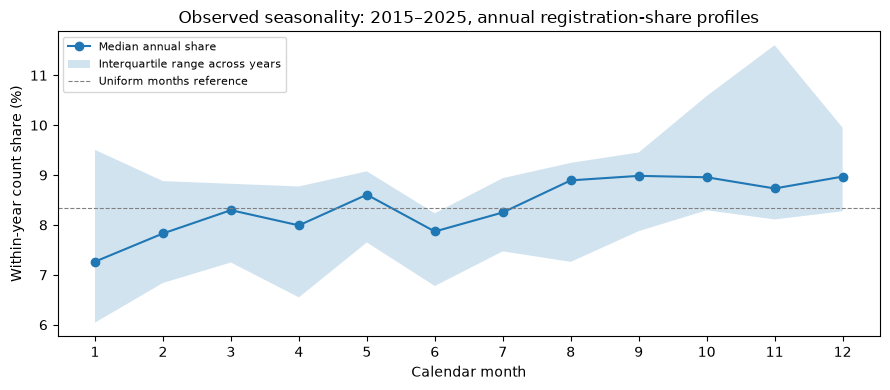

,month,median_month_share,p25_share,p75_share,years
0,1,0.072647,0.060423,0.095061,11
1,2,0.078294,0.068372,0.088791,11
2,3,0.082966,0.072474,0.088253,11
3,4,0.079917,0.065480,0.087722,11
4,5,0.086066,0.076489,0.090751,11
5,6,0.078689,0.067763,0.082347,11
6,7,0.082501,0.074710,0.089385,11
7,8,0.088939,0.072601,0.092443,11
8,9,0.089839,0.078753,0.094528,11
9,10,0.089559,0.082940,0.105838,11


In [24]:
month_counts=p0.groupby(['year','month'],observed=True).agg(n=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index()
month_counts['days']=month_counts.apply(lambda r:calendar.monthrange(int(r.year),int(r.month))[1],axis=1)
month_counts['n_per_calendar_day']=month_counts.n/month_counts.days
month_counts['within_year_share']=month_counts.n/month_counts.groupby('year').n.transform('sum')
month_counts['quarter']=(month_counts.month-1)//3+1
activity_seasonality=month_counts
monthly_profile=month_counts.loc[month_counts.year.between(2015,2025)].groupby('month').agg(median_month_share=('within_year_share','median'),p25_share=('within_year_share',lambda s:s.quantile(.25)),p75_share=('within_year_share',lambda s:s.quantile(.75)),years=('year','nunique')).reset_index()
fig,ax=plt.subplots(figsize=(9,4));ax.plot(monthly_profile.month,monthly_profile.median_month_share*100,marker='o',label='Median annual share');ax.fill_between(monthly_profile.month,monthly_profile.p25_share*100,monthly_profile.p75_share*100,alpha=.2,label='Interquartile range across years');ax.axhline(100/12,ls='--',color='gray',lw=.8,label='Uniform months reference');ax.set(title='Observed seasonality: 2015–2025, annual registration-share profiles',xlabel='Calendar month',ylabel='Within-year count share (%)',xticks=np.arange(1,13));ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'03_seasonality.png',dpi=150);plt.show()
display(monthly_profile)

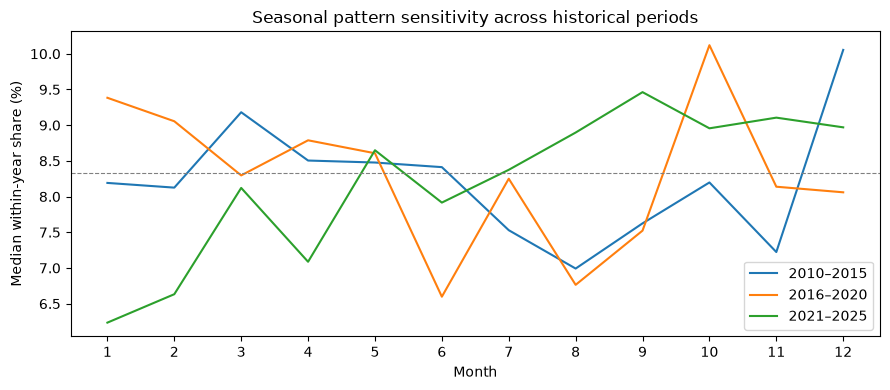

,reg,month,median_within_reg_share,years
0,Off-Plan,1,0.056103,5
1,Off-Plan,2,0.059047,5
2,Off-Plan,3,0.073832,5
3,Off-Plan,4,0.065721,5
4,Off-Plan,5,0.075455,5
5,Off-Plan,6,0.076766,5
6,Off-Plan,7,0.076528,5
7,Off-Plan,8,0.098152,5
8,Off-Plan,9,0.105384,5
9,Off-Plan,10,0.096589,5


In [25]:
month_reg=p0.groupby(['year','month','reg'],observed=True).size().rename('n').reset_index()
month_reg['share_within_reg_year']=month_reg.n/month_reg.groupby(['year','reg']).n.transform('sum')
season_rows=[]
for label,a,b in [('2010–2015',2010,2015),('2016–2020',2016,2020),('2021–2025',2021,2025)]:
    z=month_counts.loc[month_counts.year.between(a,b)]
    for m in range(1,13):
        w=z.loc[z.month.eq(m),'within_year_share']
        season_rows.append(dict(period=label,month=m,median_share=float(w.median()) if len(w) else np.nan,years=int(w.count())))
activity_seasonality_stability=pd.DataFrame(season_rows)
season_registration_sensitivity=(month_reg.loc[month_reg.year.between(2021,2025)].groupby(['reg','month']).agg(median_within_reg_share=('share_within_reg_year','median'),years=('year','nunique')).reset_index())
fig,ax=plt.subplots(figsize=(9,4))
for period,sub in activity_seasonality_stability.groupby('period'):
    ax.plot(sub.month,100*sub.median_share,label=period)
ax.axhline(100/12,color='gray',ls='--',lw=.8);ax.set(title='Seasonal pattern sensitivity across historical periods',xlabel='Month',ylabel='Median within-year share (%)',xticks=np.arange(1,13));ax.legend();fig.tight_layout();fig.savefig(FIG/'03_seasonality_stability.png',dpi=150);plt.show()
display(season_registration_sensitivity.head(12))

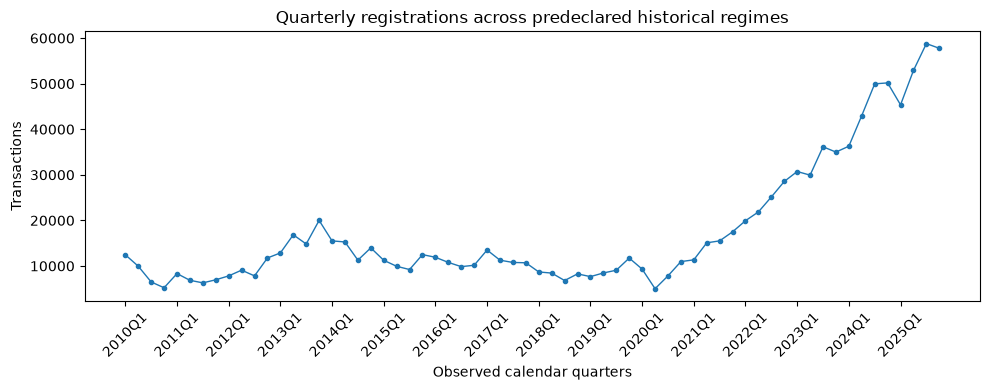

,period,first_year,last_year,quarters,median_quarter_count,median_yoy_pct,positive_yoy_fraction,max_positive_run
0,2010–2015,2010,2015,24,10599.5,-4.553314,0.375,8
1,2016–2020,2016,2020,20,9581.5,2.418784,0.550,4
2,2021–2025,2021,2025,20,32859.5,43.530069,1.000,20


In [26]:
d=q[['year','quarter','period','transactions','yoy_pct','yoy_delta_n','rolling_4q_n']].copy().sort_values(['year','quarter'])
d['positive_yoy']=d.yoy_delta_n>0;d['negative_yoy']=d.yoy_delta_n<0
# Durations of consecutive positive/negative YoY observations; missing YoY breaks the sequence.
state=np.where(d.yoy_delta_n.isna(),'undefined',np.where(d.yoy_delta_n>0,'expansion',np.where(d.yoy_delta_n<0,'contraction','flat')))
d['observed_state']=state
run_ids=(d.observed_state!=d.observed_state.shift()).cumsum()
d['same_state_run_quarters']=d.groupby(run_ids).cumcount()+1
activity_regime_diagnostics=d
# Predeclared period blocks—not fitted structural break dates.
blocks=[(2010,2015),(2016,2020),(2021,2025)]
regime_summary=pd.DataFrame([dict(period=f'{a}–{b}',first_year=a,last_year=b,quarters=len(d.loc[d.year.between(a,b)]),median_quarter_count=float(d.loc[d.year.between(a,b),'transactions'].median()),median_yoy_pct=float(d.loc[d.year.between(a,b),'yoy_pct'].median()),positive_yoy_fraction=float(d.loc[d.year.between(a,b),'positive_yoy'].mean()),max_positive_run=int(d.loc[d.year.between(a,b)&d.observed_state.eq('expansion'),'same_state_run_quarters'].max()) if d.loc[d.year.between(a,b)&d.observed_state.eq('expansion')].shape[0] else 0) for a,b in blocks])
fig,ax=plt.subplots(figsize=(10,4));ax.plot(np.arange(len(d)),d.transactions,marker='.',lw=1);ax.set(title='Quarterly registrations across predeclared historical regimes',xlabel='Observed calendar quarters',ylabel='Transactions');ax.set_xticks(np.arange(0,len(d),4),d.period.iloc[::4],rotation=45);fig.tight_layout();fig.savefig(FIG/'03_activity_regimes.png',dpi=150);plt.show()
display(regime_summary)

## 37 — Regime and seasonality decision

Descriptions of persistent registration growth are supported by counts and consecutive-quarter comparisons, with correct windows and denominators. A changing seasonal profile is a **measurement** result, potentially altered by category mix or administrative timing. No data-driven break-date hypothesis, statistical causal attribution, or macroeconomic explanation will be published as validated. Large percentage changes in early sparse periods remain qualified by baseline counts.

## 38 — Exploratory RQ06: chronological research contract

The only candidate predictive relationship is between **past community registration activity** and **later observed residential median AED/sqm movement**. A quarterly constant-quality price index is **not** supplied by Notebook 02; it qualified broad and size-controlled *annual* matched changes. Quarterly community medians are composition-sensitive, even if their sample sizes are adequate. The eligibility of two adjacent quarters must not depend on *future price outcomes* during model selection.

**Gate:** require a meaningful number of communities with consecutive periods, minimum residential transactions in both price periods, chronological separation, and an explicit baseline comparison. If unsupported, return RQ06 **INCONCLUSIVE**. If feasible, use a single transparent pooled linear model with chronological expanding-window evaluation, never a causal model. No hyperparameter search across the test window or opportunistic threshold changes.

In [27]:
# Diagnostic grid uses only P1 Strict; no bedroom attrition and no P0 counts substituted for prices.
p1=engineered.loc[strict_mask,['year','quarter','area_id','price_per_sqm']].copy()
p1['year']=p1.year.astype(int);p1['quarter']=p1.quarter.astype(int)
p1['area_key']=p1.area_id.astype('string')
p1=p1.loc[p1.area_key.notna() & np.isfinite(p1.price_per_sqm) & p1.price_per_sqm.gt(0)].copy()
p1['qcode']=p1.year*4+p1.quarter
price_q=p1.groupby(['area_key','qcode'],observed=True).agg(price_n=('price_per_sqm','size'),median_psm=('price_per_sqm','median')).reset_index()
activity_q=community_activity_panel[['year','quarter','area_key','transactions']].copy()
activity_q['qcode']=activity_q.year*4+activity_q.quarter
# Construct a complete community-quarter grid only for observed registrations; missing 0-activity quarters are not imputed.
price_q['next_qcode']=price_q.qcode+1
next_price=price_q[['area_key','qcode','price_n','median_psm']].rename(columns={'qcode':'next_qcode','price_n':'next_price_n','median_psm':'next_median_psm'})
lead=price_q.merge(next_price,on=['area_key','next_qcode'],how='inner',validate='one_to_one')
lead=lead.merge(activity_q[['area_key','qcode','transactions']],on=['area_key','qcode'],how='left',validate='one_to_one')
lead['future_log_median_change']=np.log(lead.next_median_psm/lead.median_psm)
lead['log_activity']=np.log1p(lead.transactions)
lead['year']=((lead.qcode-1)//4).astype(int)
lead['quarter']=((lead.qcode-1)%4+1).astype(int)
# Predeclared minimum counts: descriptive support only, not within-property matching.
MIN_PRICE_QUARTER_N=20
supported_lead=lead.loc[(lead.price_n>=MIN_PRICE_QUARTER_N)&(lead.next_price_n>=MIN_PRICE_QUARTER_N)&lead.transactions.notna()].copy()
lead_lag_feasibility=pd.DataFrame([dict(all_adjacent_community_quarters=len(lead),supported_community_quarters=len(supported_lead),distinct_supported_communities=int(supported_lead.area_key.nunique()),supported_2018_2021=int(supported_lead.year.between(2018,2021).sum()),supported_2022_2023=int(supported_lead.year.between(2022,2023).sum()),supported_2024_2025=int(supported_lead.year.between(2024,2025).sum()),minimum_transactions_per_price_quarter=MIN_PRICE_QUARTER_N,price_outcome='UNADJUSTED community median AED/sqm change; composition-sensitive')])
# Conservative feasibility: sufficient chronological training and evaluation, enough geographic units.
lg=lead_lag_feasibility.iloc[0]
RQ06_FEASIBLE=bool(lg.distinct_supported_communities>=30 and lg.supported_2018_2021>=200 and lg.supported_2022_2023>=100 and lg.supported_2024_2025>=100)
print('RQ06 raw-price exploratory gate:', 'PASSES (composition-sensitive only)' if RQ06_FEASIBLE else 'INCONCLUSIVE — insufficient support')
display(lead_lag_feasibility)

RQ06 raw-price exploratory gate: PASSES (composition-sensitive only)


,all_adjacent_community_quarters,supported_community_quarters,distinct_supported_communities,supported_2018_2021,supported_2022_2023,supported_2024_2025,minimum_transactions_per_price_quarter,price_outcome
0,4471,2399,70,620,410,414,20,UNADJUSTED community median AED/sqm change; co...


In [28]:
# Leakage-controlled chronological benchmark: predict next quarter's *raw* community median log change.
# Any strong statement remains prohibited because community median composition changes.
# Plain least-squares benchmark avoids introducing a new modeling dependency.
def linear_predict(train,test,features):
    x=np.column_stack([np.ones(len(train)),train[features].to_numpy(dtype=float)])
    z=np.column_stack([np.ones(len(test)),test[features].to_numpy(dtype=float)])
    coefficients=np.linalg.lstsq(x,train.future_log_median_change.to_numpy(dtype=float),rcond=None)[0]
    return z@coefficients
activity_lead_lag_validation=pd.DataFrame()
if RQ06_FEASIBLE:
    observations=supported_lead.copy().sort_values(['qcode','area_key'])
    # Lagged community outcome: known at the end of quarter t, never at t+1.
    prev=price_q[['area_key','qcode','median_psm']].copy()
    prev['qcode']+=1;prev=prev.rename(columns={'median_psm':'prev_median_psm'})
    observations=observations.merge(prev,on=['area_key','qcode'],how='left',validate='one_to_one')
    observations['past_log_price_change']=np.log(observations.median_psm/observations.prev_median_psm)
    # Activities are available through t; include log count and 4-quarter-lag count to control for category scale.
    prior=activity_q[['area_key','qcode','transactions']].copy();prior['qcode']+=4;prior=prior.rename(columns={'transactions':'n_four_quarters_ago'})
    observations=observations.merge(prior,on=['area_key','qcode'],how='left',validate='one_to_one')
    observations['yoy_log_activity_change']=np.log1p(observations.transactions)-np.log1p(observations.n_four_quarters_ago)
    observations=observations.dropna(subset=['past_log_price_change','yoy_log_activity_change','future_log_median_change'])
    observations=observations.loc[np.isfinite(observations[['past_log_price_change','yoy_log_activity_change','future_log_median_change']]).all(axis=1)]
    # Fold origins are declared beforehand; train rows' outcomes cannot overlap future-quarter test period.
    fold_results=[]
    for test_start,test_end in [(2022,2023),(2024,2025)]:
        train=observations.loc[(observations.year>=2016)&(observations.year<test_start-1)].copy()
        test=observations.loc[observations.year.between(test_start,test_end)].copy()
        if len(train)<200 or len(test)<100 or train.area_key.nunique()<25 or test.area_key.nunique()<25:
            fold_results.append(dict(test_period=f'{test_start}–{test_end}',train_n=len(train),test_n=len(test),status='INCONCLUSIVE',reason='Chronological minimum support not met'))
            continue
        features_base=['past_log_price_change']
        features_aug=['past_log_price_change','yoy_log_activity_change']
        y=test.future_log_median_change.to_numpy(dtype=float)
        pb=linear_predict(train,test,features_base)
        pa=linear_predict(train,test,features_aug)
        mae_base=float(np.mean(np.abs(y-pb)))
        mae_aug=float(np.mean(np.abs(y-pa)))
        fold_results.append(dict(test_period=f'{test_start}–{test_end}',train_n=len(train),test_n=len(test),status='ESTIMATED_EXPLORATORY',mae_baseline=mae_base,mae_activity=mae_aug,mae_improvement_pct=100*(mae_base-mae_aug)/mae_base if mae_base>0 else np.nan,directional_baseline=float(np.mean(np.sign(pb)==np.sign(y))),directional_activity=float(np.mean(np.sign(pa)==np.sign(y))),reason='Raw quarterly medians; no constant-quality identification'))
    activity_lead_lag_validation=pd.DataFrame(fold_results)
else:
    activity_lead_lag_validation=pd.DataFrame([dict(status='INCONCLUSIVE',reason='Feasibility gate failed; no model fitted')])
print('RQ06 chronology and restrictions: evaluation features end at quarter t; target is quarter t+1, but price outcomes remain composition-sensitive.')
display(activity_lead_lag_validation)

RQ06 chronology and restrictions: evaluation features end at quarter t; target is quarter t+1, but price outcomes remain composition-sensitive.


,test_period,train_n,test_n,status,mae_baseline,mae_activity,mae_improvement_pct,directional_baseline,directional_activity,reason
0,2022–2023,744,406,ESTIMATED_EXPLORATORY,0.106655,0.105256,1.311397,0.421182,0.445813,Raw quarterly medians; no constant-quality ide...
1,2024–2025,1125,411,ESTIMATED_EXPLORATORY,0.074469,0.075726,-1.687335,0.532847,0.498783,Raw quarterly medians; no constant-quality ide...


In [29]:
ok=activity_lead_lag_validation.loc[activity_lead_lag_validation.status.eq('ESTIMATED_EXPLORATORY')].copy()
reliable=bool(RQ06_FEASIBLE and len(ok)>=2 and ok.mae_improvement_pct.notna().all() and (ok.mae_improvement_pct>0).all())
activity_lead_lag_research_decisions=pd.DataFrame([dict(research_question='RQ06',decision='QUALIFIED' if reliable else 'INCONCLUSIVE',model_comparison='Raw community-quarter median price change',out_of_time_supported_folds=len(ok),all_supported_folds_improve=bool(reliable),restriction='Even when observed held-out MAE improves, composition-sensitive raw medians and observational associations do not identify causal effects or constant-quality price appreciation.')])
display(activity_lead_lag_research_decisions)

,research_question,decision,model_comparison,out_of_time_supported_folds,all_supported_folds_improve,restriction
0,RQ06,INCONCLUSIVE,Raw community-quarter median price change,2,False,"Even when observed held-out MAE improves, comp..."


## 42 — Robustness policy

Vary period **before interpreting effects** (2021/2025 and 2020/2025), cohort (P0, P1 Core, P1 Strict), geography universe (all known, fixed 2021, common), and baseline activity support (1/10/30/100/300 registrations). These are **different target populations**; direction agreement is not proof of causal transportability. Retain unknown registration in P0. Seasonal diagnostics compare 2010–15, 2016–20 and 2021–25; annual count/value and quarterly counterparts must reconcile. Do not auto-upgrade exploratory predictive signals.

In [30]:
sensitivity_rows=[]
for start,end in [(2021,2025),(2020,2025)]:
    for pop_label,mask in [('P0',p0_mask),('P1 Core',p1_mask),('P1 Strict',strict_mask)]:
        frame=engineered.loc[mask & historical,['year','reg_type_label']].copy();frame['year']=frame.year.astype(int);frame['reg']=frame.reg_type_label.where(frame.reg_type_label.isin(['Ready','Off-Plan']),'Unknown')
        v=offplan_scale_share(frame,start,end)
        if v:
            sensitivity_rows.append(dict(comparison=f'{start}–{end}',population=pop_label,n_start=v['n0'],n_end=v['n1'],count_growth_pct=100*(v['n1']/v['n0']-1),offplan_share_delta_pp=100*(v['offplan_share1']-v['offplan_share0']),offplan_scale_component=v['market_scale_component'],offplan_share_component=v['share_reallocation_component']))
activity_research_sensitivity=pd.DataFrame(sensitivity_rows)
# Geographic sensitivity must use the population-specific P0 known-coverage comparison.
geo=community_universe_sensitivity.pivot(index='universe',columns='year',values='count_hhi')
geo['delta_hhi']=geo[T1]-geo[T0]
activity_geography_sensitivity=geo.reset_index()
display(activity_research_sensitivity);display(activity_geography_sensitivity)

,comparison,population,n_start,n_end,count_growth_pct,offplan_share_delta_pp,offplan_scale_component,offplan_share_component
0,2021–2025,P0,59424,214803,261.475162,23.225551,79163.633700,31845.366300
1,2021–2025,P1 Core,46941,182395,288.562238,24.957464,80458.774751,28618.225249
2,2021–2025,P1 Strict,46302,178962,286.510302,25.070718,78670.348353,28237.651647
3,2020–2025,P0,33102,214803,548.912452,18.585315,96790.037354,23036.962646
4,2020–2025,P1 Core,26421,182395,590.341017,22.091912,94882.276644,23065.723356
5,2020–2025,P1 Strict,26137,178962,584.707503,22.126459,92878.426579,22690.573421


year,universe,2021,2025,delta_hhi
0,all_known,0.042678,0.031983,-0.010694
1,common_2021_2025,0.043992,0.033605,-0.010387
2,fixed_2021,0.042678,0.033605,-0.009073


In [31]:
# Research restrictions are attached to observed magnitudes; these are not hypothesis-test p values.
core=activity_research_sensitivity.loc[activity_research_sensitivity.comparison.eq('2021–2025')]
directions=core.offplan_share_delta_pp.map(np.sign).dropna().unique()
geo_signs=activity_geography_sensitivity.delta_hhi.map(np.sign).dropna().unique()
robustness_rows=[dict(claim='Activity count expansion',population='P0 historical',comparison='2021–2025',decision='SUPPORTED',evidence='Exact count reconciliation',restriction='Registered sales count, not unique dwellings or buyer demand'),dict(claim='Off-Plan share change',population='P0; P1 sensitivity',comparison='2021–2025',decision='SUPPORTED' if len(directions)<=1 else 'QUALIFIED',evidence='Exact scale/share and within/between decompositions',restriction='Registration category shares, not construction or cash receipts'),dict(claim='Geographic concentration change',population='Known-community P0',comparison='2021–2025',decision='SUPPORTED' if len(geo_signs)<=1 else 'QUALIFIED',evidence='All-known, common and fixed-2021 universes',restriction='Geography universe, incomplete identifiers, no stock denominators'),dict(claim='Activity leading later price',population='P1 Strict raw community medians',comparison='Chronological quarters',decision=activity_lead_lag_research_decisions.decision.iloc[0],evidence='Out-of-time benchmark; conditional feasibility',restriction='Exploratory observational, raw median composition-sensitive')]
activity_research_robustness_gate=pd.DataFrame(robustness_rows)
display(activity_research_robustness_gate)

,claim,population,comparison,decision,evidence,restriction
0,Activity count expansion,P0 historical,2021–2025,SUPPORTED,Exact count reconciliation,"Registered sales count, not unique dwellings o..."
1,Off-Plan share change,P0; P1 sensitivity,2021–2025,SUPPORTED,Exact scale/share and within/between decomposi...,"Registration category shares, not construction..."
2,Geographic concentration change,Known-community P0,2021–2025,SUPPORTED,"All-known, common and fixed-2021 universes","Geography universe, incomplete identifiers, no..."
3,Activity leading later price,P1 Strict raw community medians,Chronological quarters,INCONCLUSIVE,Out-of-time benchmark; conditional feasibility,"Exploratory observational, raw median composit..."


## 45 — Validation and research acceptance contract

All critical source, time, count/value, category and geographic reconciliations must pass before exporting accepted evidence. Model feasibility is **not** a critical notebook-execution failure: when RQ06 is unsupported, that research claim becomes **INCONCLUSIVE**. Derived tables must not silently alter historical P0 or source rows. Unknown registration/geography are accounted for explicitly; a 2026 procedure-metadata discontinuity remains outside this completed-year analysis.

Each exported result retains its target population and date grain; share decompositions report exact arithmetic with no causal claims. No synthetic confidence interval is attached to a complete frozen administrative count.

In [32]:

# ============================================================
# CELL 46 — Comprehensive Research Validation
# ============================================================

validation_rows = []


def check(label, condition, details=""):
    valid = bool(condition)

    validation_rows.append({
        "check": label,
        "passed": valid,
        "details": str(details)
    })

    if not valid:
        raise AssertionError(
            f"Critical audit failure: {label}: {details}"
        )


# Read the actual computed decomposition result rather
# than relying on a temporary variable from Cell 16.
assert len(offplan_property_mix_decomposition) == 1, (
    "Expected one primary Off-Plan composition summary."
)

mix_summary = offplan_property_mix_decomposition.iloc[0]

# Source integrity and analytical populations.
check("Source SHA", source.sha256 == SHA)

check(
    "Source validation passed",
    validation.passed
)

check(
    "Source no mutation",
    all(
        raw[c].equals(engineered[c])
        for c in raw.columns
    )
)

check(
    "P1 Core subset P0",
    not (p1_mask & ~p0_mask).any()
)

check(
    "P1 Strict subset Core",
    not (strict_mask & ~p1_mask).any()
)

check(
    "P0 2010–2025 cohort",
    len(p0) == 1134513
)

check(
    "Unique transaction IDs",
    p0.transaction_id.is_unique
)

check(
    "No 2026 primary",
    p0.year.between(2010, 2025).all()
)

# Annual and quarterly reconciliation.
check(
    "Annual transaction total",
    int(activity_annual.transactions.sum()) == len(p0)
)

check(
    "Annual registered value total",
    np.isclose(
        activity_annual.registered_value_aed.sum(),
        p0.price_aed.sum(),
        rtol=1e-12
    )
)

check(
    "Quarterly transaction reconciliation",
    np.array_equal(
        activity_quarter.groupby("year")
        .transactions.sum()
        .reindex(activity_annual.year)
        .to_numpy(),
        activity_annual.transactions.to_numpy()
    )
)

check(
    "Quarterly value reconciliation",
    np.allclose(
        activity_quarter.groupby("year")
        .registered_value_aed.sum()
        .reindex(activity_annual.year)
        .to_numpy(),
        activity_annual.registered_value_aed.to_numpy(),
        rtol=1e-12
    )
)

# Registration and joint-category reconciliation.
check(
    "Registration count categories exhaustive",
    int(annual_registration.n.sum()) == len(p0)
)

check(
    "Registration value categories exhaustive",
    np.isclose(
        annual_registration.value_aed.sum(),
        p0.price_aed.sum()
    )
)

check(
    "Joint-category count exhaustive",
    int(
        activity_joint_segment_panel.transactions.sum()
    ) == len(p0)
)

check(
    "Joint-category value exhaustive",
    np.isclose(
        activity_joint_segment_panel
        .registered_value_aed.sum(),
        p0.price_aed.sum()
    )
)

# Transaction-count and value identities.
check(
    "Count times mean = registered value",
    np.allclose(
        activity_annual.transactions
        * activity_annual.mean_consideration_aed,
        activity_annual.registered_value_aed
    )
)

check(
    "Log count-value identity",
    np.nanmax(
        np.abs(
            activity_count_value_bridge
            .log_identity_residual
        )
    ) < 1e-10
)

# Ready versus Off-Plan decompositions.
check(
    "Off-Plan scale/share identity",
    np.allclose(
        offplan_scale_share_decomposition
        .reconciliation_error,
        0,
        atol=1e-8
    )
)

check(
    "Off-Plan within/between identity",
    np.isclose(
        mix_summary["offplan_share_delta"],
        (
            mix_summary["within_property_component"]
            + mix_summary["property_composition_component"]
            + mix_summary["entry_exit_residual"]
        ),
        atol=1e-12
    )
)

# Geography and coverage.
check(
    "Community counts + unknown = P0",
    np.array_equal(
        (
            activity_geography_coverage.known_geography_n
            + activity_geography_coverage.unknown_n
        ),
        activity_geography_coverage.transactions
    )
)

check(
    "Community values + unknown = P0",
    np.allclose(
        (
            activity_geography_coverage
            .known_geography_value_aed
            + activity_geography_coverage
            .unknown_value_aed
        ),
        activity_geography_coverage
        .registered_value_aed
    )
)

check(
    "Community HHI bounded",
    community_concentration_yearly.count_hhi
    .between(0, 1).all()
)

check(
    "Geographic count/value bridge",
    np.allclose(
        community_activity_growth_bridge
        .reconciliation_error,
        0,
        atol=1e-5
    )
)

check(
    "Fixed geographic universe inclusion",
    common_ids.issubset(base_ids)
    and common_ids.issubset(end_ids)
)

check(
    "Universe coverage <= 100%",
    community_universe_sensitivity
    .coverage_p0_pct.le(100 + 1e-8).all()
)

check(
    "Common growth breadth reconciles",
    int(common_panel.delta.sum())
    == int(
        community_activity_growth_bridge.query(
            "metric == 'transactions'"
        ).iloc[0].common_community_delta
    )
)

# Time-series validity.
check(
    "Seasonal year counts reconcile",
    int(activity_seasonality.n.sum()) == len(p0)
)

check(
    "Rolling quarters only contiguous",
    q.loc[
        ~q.contiguous_4q,
        "rolling_4q_n"
    ].isna().all()
)

check(
    "Temporal price predictors precede outcomes",
    (
        lead.next_qcode == lead.qcode + 1
    ).all()
)

check(
    "Lead-lag explicitly gated",
    len(activity_lead_lag_research_decisions) == 1
    and activity_lead_lag_research_decisions
    .decision.isin(
        ["QUALIFIED", "INCONCLUSIVE"]
    ).all()
)

check(
    "Research decisions non-causal",
    not activity_research_robustness_gate
    .restriction.isna().any()
)

# Final validation registry.
activity_research_validation = pd.DataFrame(
    validation_rows
)

assert activity_research_validation[
    "check"
].is_unique

display(activity_research_validation)

passed_checks = int(
    activity_research_validation["passed"].sum()
)

total_checks = len(activity_research_validation)

print(
    "Audit checks:",
    passed_checks,
    "/",
    total_checks
)

assert passed_checks == total_checks

print(
    "Validation completed successfully. "
    "All registered mathematical and logical checks passed."
)


,check,passed,details
0,Source SHA,True,
1,Source validation passed,True,
2,Source no mutation,True,
3,P1 Core subset P0,True,
4,P1 Strict subset Core,True,
5,P0 2010–2025 cohort,True,
6,Unique transaction IDs,True,
7,No 2026 primary,True,
8,Annual transaction total,True,
9,Annual registered value total,True,


Audit checks: 32 / 32
Validation completed successfully. All registered mathematical and logical checks passed.


In [33]:

# ============================================================
# Notebook 03 — Verified Research Artifact Exports
# ============================================================
# Purpose:
# - Export only validated, computed research artifacts.
# - Preserve all original in-memory research DataFrames.
# - Normalize column names for CSV/Parquet compatibility.
# - Verify exported schemas, row counts, and numeric values.
# - Prevent KeyError caused by integer year column names.
# - Never modify the frozen source dataset or src modules.
# ============================================================

# 1. Require successful research validation before exporting.
assert activity_research_validation["passed"].all(), (
    "Research validation failed. Exports are blocked."
)

# 2. Register all computed research artifacts.
exports = {
    "03_source_manifest": source_manifest,
    "03_activity_cohort_reconciliation": cohort_reconciliation,
    "03_activity_period_panel": activity_period_panel,
    "03_activity_growth_dynamics": activity_growth_dynamics,
    "03_activity_segment_growth_breadth": activity_segment_growth_breadth,
    "03_activity_segment_quarterly": activity_segment_quarterly,
    "03_activity_count_value_bridge": activity_count_value_bridge,
    "03_activity_momentum_summary": activity_momentum_summary,
    "03_registration_activity_panel": registration_activity_panel,
    "03_registration_annual": annual_registration,
    "03_registration_growth_contributions": registration_growth_contributions,
    "03_offplan_scale_share_decomposition": offplan_scale_share_decomposition,
    "03_offplan_property_mix_decomposition": offplan_property_mix_decomposition,
    "03_offplan_property_mix_detail": property_mix_detail,
    "03_offplan_mix_sensitivity": offplan_mix_sensitivity,
    "03_activity_joint_segment_panel": activity_joint_segment_panel,
    "03_joint_growth_bridge": joint_growth_bridge,
    "03_activity_segment_count_value_divergence": activity_segment_count_value_divergence,
    "03_activity_segment_participation": activity_segment_participation,
    "03_registration_procedure_diagnostics": registration_procedure_diagnostics,
    "03_procedure_crosswalk": procedure_crosswalk,
    "03_community_activity_panel": community_activity_panel,
    "03_activity_geography_coverage": activity_geography_coverage,
    "03_community_concentration_yearly": community_concentration_yearly,
    "03_community_universe_sensitivity": community_universe_sensitivity,
    "03_community_activity_growth_bridge": community_activity_growth_bridge,
    "03_community_growth_breadth": count_growth_breadth,
    "03_community_growth_threshold_sensitivity": community_growth_threshold_sensitivity,
    "03_community_growth_persistence": community_growth_persistence,
    "03_activity_seasonality": activity_seasonality,
    "03_activity_seasonality_stability": activity_seasonality_stability,
    "03_season_registration_sensitivity": season_registration_sensitivity,
    "03_activity_regime_diagnostics": activity_regime_diagnostics,
    "03_activity_regime_summary": regime_summary,
    "03_activity_lead_lag_feasibility": lead_lag_feasibility,
    "03_activity_lead_lag_validation": activity_lead_lag_validation,
    "03_activity_lead_lag_research_decisions": activity_lead_lag_research_decisions,
    "03_activity_research_sensitivity": activity_research_sensitivity,
    "03_activity_geography_sensitivity": activity_geography_sensitivity,
    "03_activity_research_robustness_gate": activity_research_robustness_gate,
    "03_activity_research_validation": activity_research_validation,
}

# 3. Ensure destination directories exist.
TABLES.mkdir(parents=True, exist_ok=True)
AGG.mkdir(parents=True, exist_ok=True)

export_rows = []
skipped_exports = []

# 4. Export and independently verify each artifact.
for name, df in exports.items():

    # Do not create placeholder artifacts for unsupported analyses.
    if df is None:
        skipped_exports.append((name, "Not estimated"))
        continue

    if not isinstance(df, pd.DataFrame):
        raise TypeError(
            f"{name}: Expected a pandas DataFrame, "
            f"received {type(df).__name__}."
        )

    if df.empty:
        skipped_exports.append((name, "Empty result"))
        continue

    # Copy so original research tables remain unchanged.
    out = df.copy(deep=True)

    # IMPORTANT FIX:
    # Integer year column labels (2021, 2025) are converted
    # to strings only in the export copy.
    #
    # This avoids Parquet/CSV column-label inconsistencies.
    out.columns = [str(col) for col in out.columns]

    assert out.columns.is_unique, (
        f"{name}: Duplicate column names after normalization."
    )

    csv_path = TABLES / f"{name}.csv"
    parquet_path = AGG / f"{name}.parquet"

    # Save both representations.
    out.to_csv(csv_path, index=False)

    out.to_parquet(
        parquet_path,
        index=False,
        engine="pyarrow",
    )

    # 5. Read both files back for verification.
    csv_check = pd.read_csv(csv_path)
    parquet_check = pd.read_parquet(
        parquet_path,
        engine="pyarrow",
    )

    # Row-count reconciliation.
    assert len(csv_check) == len(out), (
        f"{name}: CSV row-count mismatch."
    )

    assert len(parquet_check) == len(out), (
        f"{name}: Parquet row-count mismatch."
    )

    # Exact ordered schema reconciliation.
    assert list(csv_check.columns) == list(out.columns), (
        f"{name}: CSV schema mismatch."
    )

    assert list(parquet_check.columns) == list(out.columns), (
        f"{name}: Parquet schema mismatch."
    )

    # 6. Verify numerical data preserved by Parquet.
    numeric_columns = out.select_dtypes(
        include="number"
    ).columns

    for field in numeric_columns:

        original_values = pd.to_numeric(
            out[field],
            errors="coerce",
        ).to_numpy(dtype=float)

        restored_values = pd.to_numeric(
            parquet_check[field],
            errors="coerce",
        ).to_numpy(dtype=float)

        assert np.allclose(
            original_values,
            restored_values,
            rtol=1e-10,
            atol=1e-7,
            equal_nan=True,
        ), (
            f"{name}: Parquet numerical mismatch "
            f"in column '{field}'."
        )

    # Verify both files were physically written.
    assert csv_path.is_file(), (
        f"{name}: CSV file not found."
    )

    assert parquet_path.is_file(), (
        f"{name}: Parquet file not found."
    )

    assert csv_path.stat().st_size > 0, (
        f"{name}: CSV file is empty."
    )

    assert parquet_path.stat().st_size > 0, (
        f"{name}: Parquet file is empty."
    )

    # 7. Record verified export metadata.
    export_rows.append({
        "name": name,
        "rows": len(out),
        "columns": len(out.columns),
        "csv_bytes": csv_path.stat().st_size,
        "parquet_bytes": parquet_path.stat().st_size,
        "source_sha256": SHA,
        "verification": "PASS",
    })

# 8. Construct the research artifact manifest.
activity_export_manifest = pd.DataFrame(export_rows)

assert len(activity_export_manifest) > 20, (
    "Too few verified research artifacts. "
    "Inspect the skipped export list."
)

assert activity_export_manifest[
    "verification"
].eq("PASS").all(), (
    "One or more exported artifacts failed verification."
)

assert activity_export_manifest["name"].is_unique, (
    "Duplicate research artifact names detected."
)

# 9. Display final export audit.
display(activity_export_manifest)

print("=" * 65)
print("NOTEBOOK 03 — RESEARCH EXPORT VERIFICATION")
print("=" * 65)

print(
    "Research validation:",
    f"{int(activity_research_validation['passed'].sum())}/"
    f"{len(activity_research_validation)} passed"
)

print(
    "Verified research artifact pairs:",
    len(activity_export_manifest)
)

print(
    "CSV files verified:",
    len(activity_export_manifest)
)

print(
    "Parquet files verified:",
    len(activity_export_manifest)
)

print(
    "Total exported rows:",
    f"{int(activity_export_manifest['rows'].sum()):,}"
)

print(
    "Skipped artifacts:",
    len(skipped_exports)
)

if skipped_exports:
    print("\nSkipped artifact details:")

    for name, reason in skipped_exports:
        print(f"  - {name}: {reason}")

print("\nSource SHA-256:", SHA)
print("CSV destination:", TABLES)
print("Parquet destination:", AGG)

print("=" * 65)
print("EXPORT VERIFICATION COMPLETED SUCCESSFULLY")
print("=" * 65)


,name,rows,columns,csv_bytes,parquet_bytes,source_sha256,verification
0,03_source_manifest,1,9,246,6019,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
1,03_activity_cohort_reconciliation,4,2,118,1915,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
2,03_activity_period_panel,80,8,5154,7940,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
3,03_activity_growth_dynamics,64,18,12710,17952,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
4,03_activity_segment_growth_breadth,64,7,1699,5579,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
5,03_activity_segment_quarterly,383,10,25659,15523,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
6,03_activity_count_value_bridge,16,10,2469,8210,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
7,03_activity_momentum_summary,1,8,217,5657,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
8,03_registration_activity_panel,128,5,4173,5131,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS
9,03_registration_annual,32,8,2927,6493,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,PASS


NOTEBOOK 03 — RESEARCH EXPORT VERIFICATION
Research validation: 32/32 passed
Verified research artifact pairs: 41
CSV files verified: 41
Parquet files verified: 41
Total exported rows: 10,171
Skipped artifacts: 0

Source SHA-256: 8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e
CSV destination: e:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\reports\tables
Parquet destination: e:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\data\aggregates
EXPORT VERIFICATION COMPLETED SUCCESSFULLY


In [34]:

# ============================================================
# CELL 48 — Evidence-Based Research Conclusions
# ============================================================

assert activity_research_validation["passed"].all(), (
    "Final findings blocked: research validation failed."
)

def num(value):
    return format(value, ",.0f")


def direction(value, positive="increased", negative="decreased"):
    if value > 0:
        return positive
    if value < 0:
        return negative
    return "remained unchanged"


# Retrieve validated research results directly.
annual_index = activity_annual.set_index("year")

y0 = annual_index.loc[T0]
y1 = annual_index.loc[T1]

reg_summary = offplan_scale_share_decomposition.loc[
    offplan_scale_share_decomposition["start"].eq(T0)
    & offplan_scale_share_decomposition["end"].eq(T1)
].iloc[0]

mix_summary = offplan_property_mix_decomposition.loc[
    offplan_property_mix_decomposition["start"].eq(T0)
    & offplan_property_mix_decomposition["end"].eq(T1)
].iloc[0]

concentration = (
    community_concentration_yearly.set_index("year")
)

con0 = concentration.loc[T0]
con1 = concentration.loc[T1]

growth = count_growth_breadth.iloc[0]

geo_bridge = community_activity_growth_bridge.loc[
    community_activity_growth_bridge[
        "metric"
    ].eq("transactions")
].iloc[0]

geo_decision = (
    activity_research_robustness_gate.loc[
        activity_research_robustness_gate[
            "claim"
        ].eq("Geographic concentration change"),
        "decision"
    ].iloc[0]
)

prediction_decision = (
    activity_lead_lag_research_decisions[
        "decision"
    ].iloc[0]
)

momentum = activity_momentum_summary.iloc[0]

checks = int(
    activity_research_validation["passed"].sum()
)

# Independent validation of the decomposition inputs.
assert np.isclose(
    mix_summary["offplan_share_delta"],
    (
        mix_summary["within_property_component"]
        + mix_summary["property_composition_component"]
        + mix_summary["entry_exit_residual"]
    ),
    atol=1e-12
)

assert np.isclose(
    reg_summary["delta_offplan"],
    (
        reg_summary["market_scale_component"]
        + reg_summary["share_reallocation_component"]
    ),
    atol=1e-8
)

# Construct dynamic findings from computed data.
findings = [

    {
        "claim_id": "ACT01",
        "research_question": "Growth dynamics",
        "decision": "SUPPORTED",
        "interpretation": (
            f"P0 registrations {direction(y1.transactions-y0.transactions)} "
            f"from {num(y0.transactions)} ({T0}) "
            f"to {num(y1.transactions)} ({T1}); "
            f"signed change {y1.transactions-y0.transactions:+,.0f}. "
            f"Nominal registered consideration moved "
            f"from AED {y0.registered_value_aed/1e9:.2f}B "
            f"to AED {y1.registered_value_aed/1e9:.2f}B."
        ),
        "restriction": (
            "Registrations are not unique dwellings or independently "
            "validated housing demand. Registered consideration "
            "is not developer cash receipts or capital inflows."
        )
    },

    {
        "claim_id": "ACT02",
        "research_question": "Growth persistence",
        "decision": "QUALIFIED",
        "interpretation": (
            f"Between 2022 and 2025, "
            f"{int(momentum.positive_yoy_quarters)} "
            f"of {int(momentum.quarters)} observed quarters "
            f"recorded positive same-quarter transaction growth. "
            f"Median quarterly YoY growth was "
            f"{momentum.median_yoy_pct:+.1f}%."
        ),
        "restriction": (
            "Observed same-quarter growth is descriptive. "
            "Historical registration practices, source coverage "
            "and overlapping time-series dependence limit "
            "broader economic-cycle interpretations."
        )
    },

    {
        "claim_id": "REG01",
        "research_question": "RQ05",
        "decision": "SUPPORTED",
        "interpretation": (
            f"Off-Plan transaction share moved from "
            f"{100*reg_summary.offplan_share0:.2f}% "
            f"to {100*reg_summary.offplan_share1:.2f}%. "
            f"Registered Off-Plan count changed by "
            f"{reg_summary.delta_offplan:+,.0f}. "
            f"The exact symmetric accounting components were "
            f"{reg_summary.market_scale_component:+,.1f} "
            f"registrations from market-scale change and "
            f"{reg_summary.share_reallocation_component:+,.1f} "
            f"from share reallocation."
        ),
        "restriction": (
            "These are exact accounting components, not "
            "independently identified causal drivers. "
            "Off-Plan registrations are not developer receipts "
            "or proof of completed construction."
        )
    },

    {
        "claim_id": "REG02",
        "research_question": "RQ05",
        "decision": "SUPPORTED",
        "interpretation": (
            f"Off-Plan count share changed by "
            f"{100*mix_summary.offplan_share_delta:+.2f} "
            f"percentage points: "
            f"{100*mix_summary.within_property_component:+.2f} "
            f"pp within property categories, "
            f"{100*mix_summary.property_composition_component:+.2f} "
            f"pp from property-category composition, and "
            f"{100*mix_summary.entry_exit_residual:+.2f} "
            f"pp from the entry/exit residual."
        ),
        "restriction": (
            "The decomposition uses broad observed property "
            "categories. It does not control for identical "
            "physical-property quality or establish causality."
        )
    },

    {
        "claim_id": "GEO01",
        "research_question": "RQ04",
        "decision": (
            "SUPPORTED"
            if geo_decision == "SUPPORTED"
            else "QUALIFIED"
        ),
        "interpretation": (
            f"Known-community transaction-count HHI "
            f"{direction(con1.count_hhi-con0.count_hhi)} "
            f"from {con0.count_hhi:.5f} ({T0}) "
            f"to {con1.count_hhi:.5f} ({T1}); "
            f"signed difference "
            f"{con1.count_hhi-con0.count_hhi:+.5f}."
        ),
        "restriction": (
            "HHI measures concentration among observed "
            "community identifiers. It does not measure "
            "housing-stock turnover, stable physical "
            "boundaries or investment performance."
        )
    },

    {
        "claim_id": "GEO02",
        "research_question": "RQ04",
        "decision": "QUALIFIED",
        "interpretation": (
            f"Among {int(growth.common_communities)} "
            f"communities observed in both endpoints, "
            f"{int(growth['expanding'])} increased "
            f"registered transactions and "
            f"{int(growth['contracting'])} declined. "
            f"The five largest positive contributors "
            f"accounted for "
            f"{100*growth.top5_fraction_of_positive:.1f}% "
            f"of positive signed growth. "
            f"Observed entrant communities contributed "
            f"{geo_bridge.observed_entrants:+,.0f} "
            f"registrations."
        ),
        "restriction": (
            "Community participation is based on observed "
            "source-area identifiers. Unweighted breadth "
            "and base-year activity screens have their own "
            "denominators. Observed geographic entry does "
            "not prove newly constructed housing supply."
        )
    },

    {
        "claim_id": "RQ06",
        "research_question": "RQ06",
        "decision": prediction_decision,
        "interpretation": (
            "The chronological raw-median activity model "
            + (
                "showed repeated incremental improvement "
                "in the supported evaluation comparisons."
                if prediction_decision == "QUALIFIED"
                else (
                    "did not establish reliable incremental "
                    "predictive information; the stronger "
                    "predictive claim is withheld."
                )
            )
        ),
        "restriction": (
            "The target is a composition-sensitive "
            "community-quarter price measure, not a "
            "validated constant-quality price index. "
            "Predictive associations are not causal."
        )
    }
]

activity_research_findings = pd.DataFrame(findings)

# Findings registry checks.
valid_decisions = {
    "SUPPORTED",
    "QUALIFIED",
    "INCONCLUSIVE",
    "BLOCKED"
}

assert activity_research_findings[
    "decision"
].isin(valid_decisions).all()

assert activity_research_findings[
    "claim_id"
].is_unique

assert not activity_research_findings[
    ["interpretation", "restriction"]
].isna().any().any()

# Export final research findings.
findings_csv = TABLES / "03_research_findings.csv"
findings_parquet = AGG / "03_research_findings.parquet"

activity_research_findings.to_csv(
    findings_csv,
    index=False
)

activity_research_findings.to_parquet(
    findings_parquet,
    index=False,
    engine="pyarrow"
)

# Verify saved results.
csv_check = pd.read_csv(findings_csv)
parquet_check = pd.read_parquet(
    findings_parquet,
    engine="pyarrow"
)

assert len(csv_check) == len(activity_research_findings)
assert len(parquet_check) == len(activity_research_findings)

assert list(parquet_check.columns) == list(
    activity_research_findings.columns
)

pd.testing.assert_frame_equal(
    parquet_check.reset_index(drop=True),
    activity_research_findings.reset_index(drop=True)
)

# Display final executive assessment.
print(
    "## Notebook 03 — Evidence-Based Market Activity"
)

print("\nSource:", SHA)

print(
    "P0 historical transactions:",
    f"{len(p0):,}"
)

print(
    "Research period:",
    f"{T0}–{T1}"
)

for item in findings:
    print(
        f"\n{item['claim_id']} — {item['decision']}: "
        f"{item['interpretation']}"
    )

    print(
        "Restriction:",
        item["restriction"]
    )

print(
    "\nValidation:",
    checks,
    "/",
    len(activity_research_validation),
    "passed"
)

print(
    "Verified export pairs:",
    len(activity_export_manifest) + 1
)

print(
    "\nResearch handoff: subsequent community research "
    "must independently validate geographic coverage, "
    "transaction quality and comparable-property support."
)

display(
    activity_research_findings[
        [
            "claim_id",
            "research_question",
            "decision",
            "interpretation",
            "restriction"
        ]
    ]
)


## Notebook 03 — Evidence-Based Market Activity

Source: 8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e
P0 historical transactions: 1,134,513
Research period: 2021–2025

ACT01 — SUPPORTED: P0 registrations increased from 59,424 (2021) to 214,803 (2025); signed change +155,379. Nominal registered consideration moved from AED 148.35B to AED 682.33B.
Restriction: Registrations are not unique dwellings or independently validated housing demand. Registered consideration is not developer cash receipts or capital inflows.

ACT02 — QUALIFIED: Between 2022 and 2025, 16 of 16 observed quarters recorded positive same-quarter transaction growth. Median quarterly YoY growth was +40.8%.
Restriction: Observed same-quarter growth is descriptive. Historical registration practices, source coverage and overlapping time-series dependence limit broader economic-cycle interpretations.

REG01 — SUPPORTED: Off-Plan transaction share moved from 39.34% to 62.56%. Registered Off-Plan count chan

,claim_id,research_question,decision,interpretation,restriction
0,ACT01,Growth dynamics,SUPPORTED,"P0 registrations increased from 59,424 (2021) ...",Registrations are not unique dwellings or inde...
1,ACT02,Growth persistence,QUALIFIED,"Between 2022 and 2025, 16 of 16 observed quart...",Observed same-quarter growth is descriptive. H...
2,REG01,RQ05,SUPPORTED,Off-Plan transaction share moved from 39.34% t...,"These are exact accounting components, not ind..."
3,REG02,RQ05,SUPPORTED,Off-Plan count share changed by +23.23 percent...,The decomposition uses broad observed property...
4,GEO01,RQ04,SUPPORTED,Known-community transaction-count HHI decrease...,HHI measures concentration among observed comm...
5,GEO02,RQ04,QUALIFIED,Among 147 communities observed in both endpoin...,Community participation is based on observed s...
6,RQ06,RQ06,INCONCLUSIVE,The chronological raw-median activity model di...,The target is a composition-sensitive communit...
